## Cell 1 — Install Libraries

In [ ]:
import os
os.environ['PYTORCH_ALLOC_CONF'] = 'expandable_segments:True'

!pip install -q unsloth
!pip install -q --no-deps trl peft accelerate bitsandbytes
!pip install -q "transformers>=4.45.0,<5.0.0"
!pip install -q datasets scikit-learn matplotlib seaborn
print('✅ Installation done')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.8/57.8 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.2/71.2 MB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 915.6/915.6 MB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 112.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.3/322.3 MB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 115.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 33.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 869.6/869.6 kB 53.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 102.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## Cell 2 — Imports

In [ ]:
import os, gc, json, math, random, shutil, torch, torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, confusion_matrix
)
from torch.utils.data import Dataset, DataLoader
from transformers import DataCollatorWithPadding, get_linear_schedule_with_warmup
from unsloth import FastLanguageModel
from peft import PeftModel
import bitsandbytes as bnb

print('✅ All imports done')
print(f'GPU : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU"}')
print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB'
      if torch.cuda.is_available() else '')

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
✅ All imports done
GPU : Tesla T4
VRAM: 15.6 GB


## Cell 3 — Configuration

In [ ]:
# ══════════════════════════════════════════════════
# PATHS
# ══════════════════════════════════════════════════
DATA_PATH       = '/content/drive/MyDrive/IT Support Ticket Data.csv'
CHECKPOINT_BASE = '/content/drive/MyDrive/llama32-ticket-cls-v2'

# ══════════════════════════════════════════════════
# MODEL
# Paper evidence: Base (non-instruct) = F1=0.860
# Instruct = F1=0.601 (Table 2, Yousefiramandi & Cooney 2025)
# ══════════════════════════════════════════════════
MODEL_NAME  = 'unsloth/Llama-3.2-3B-bnb-4bit'
MAX_SEQ_LEN = 256   # covers 99.4% of IT tickets

# ══════════════════════════════════════════════════
# DATA SPLIT  (same as Classical ML for fair comparison)
# ══════════════════════════════════════════════════
RANDOM_STATE = 42
TEST_SIZE    = 0.2
VAL_SIZE     = 0.5

# ══════════════════════════════════════════════════

# ══════════════════════════════════════════════════
STAGE_SIZE = 2800
NUM_STAGES = 7

# ══════════════════════════════════════════════════
# TRAINING HYPERPARAMETERS
# Source: paper Table 1 + Unsloth docs
# ══════════════════════════════════════════════════
BATCH_SIZE              = 2
EVAL_BATCH_SIZE         = 8
GRAD_ACCUM              = 16    # FIX: was 8 → effective batch = 32 (more stable)
MAX_EPOCHS              = 3     # overfitting at ep3, no increase justified
EARLY_STOPPING_PATIENCE = 2     # FIX: was 1. Paper uses patience=2
WEIGHT_DECAY            = 0.01  # paper Table 1
MAX_GRAD_NORM           = 1.0   # FIX: was 0.3. Paper Table 1 uses 1.0

# ══════════════════════════════════════════════════
# LORA TARGET MODULES
# All 7 major linear layers (paper + Unsloth docs)
# ══════════════════════════════════════════════════
LORA_TARGET_MODULES = [
    'q_proj', 'k_proj', 'v_proj', 'o_proj',
    'gate_proj', 'up_proj', 'down_proj',
]

# ══════════════════════════════════════════════════
# HPT CONFIGS
# Key fixes vs previous version:
#   alpha = 2*r  (paper Table 1: r=8 alpha=16 → alpha=2r)
#   dropout = 0.05 (paper Table 1)
#   lr = 2e-4 (paper + Unsloth docs)
# ══════════════════════════════════════════════════
LORA_CONFIGS = [
    # Paper best: r=8, alpha=16 (=2r), F1=0.860
    {'name': 'LoRA_r8',  'r': 8,  'alpha': 16, 'lr': 2e-4, 'dropout': 0.05},
    # Second: r=16, alpha=32 (=2r)
    {'name': 'LoRA_r16', 'r': 16, 'alpha': 32, 'lr': 2e-4, 'dropout': 0.05},
    # Third: r=32, alpha=64 (=2r) — higher capacity, more VRAM
    {'name': 'LoRA_r32', 'r': 32, 'alpha': 64, 'lr': 2e-4, 'dropout': 0.05},
]

# ══════════════════════════════════════════════════
# CLASSES
# ══════════════════════════════════════════════════
DEPARTMENTS = [
    'Billing and Payments', 'Customer Service', 'General Inquiry',
    'Human Resources', 'IT Support', 'Product Support',
    'Returns and Exchanges', 'Sales and Pre-Sales',
    'Service Outages and Maintenance', 'Technical Support',
]
LABEL2ID = {d: i for i, d in enumerate(DEPARTMENTS)}
ID2LABEL = {i: d for d, i in LABEL2ID.items()}
NUM_CLASSES = len(DEPARTMENTS)

print('✅ Config loaded')
print(f'   Model       : {MODEL_NAME}')
print(f'   Stage size  : {STAGE_SIZE} × {NUM_STAGES} = {STAGE_SIZE*NUM_STAGES} samples')
print(f'   Eff. batch  : {BATCH_SIZE} × {GRAD_ACCUM} = {BATCH_SIZE*GRAD_ACCUM}')
print(f'   Patience    : {EARLY_STOPPING_PATIENCE} (per-stage)')
print(f'   Grad norm   : {MAX_GRAD_NORM}')
print()
print('HPT Configs:')
for c in LORA_CONFIGS:
    print(f'  {c["name"]}: r={c["r"]} alpha={c["alpha"]} (={c["alpha"]//c["r"]}r) '
          f'dropout={c["dropout"]} lr={c["lr"]}')

✅ Config loaded
   Model       : unsloth/Llama-3.2-3B-bnb-4bit
   Stage size  : 2800 × 7 = 19600 samples
   Eff. batch  : 2 × 16 = 32
   Patience    : 2 (per-stage)
   Grad norm   : 1.0

HPT Configs:
  LoRA_r8: r=8 alpha=16 (=2r) dropout=0.05 lr=0.0002
  LoRA_r16: r=16 alpha=32 (=2r) dropout=0.05 lr=0.0002
  LoRA_r32: r=32 alpha=64 (=2r) dropout=0.05 lr=0.0002


## Cell 4 — Mount Drive & Load Data

new

In [ ]:
from google.colab import drive
import os
drive.mount('/content/drive')
os.makedirs(CHECKPOINT_BASE, exist_ok=True)

df = pd.read_csv(DATA_PATH, index_col=0)
df = df.dropna(subset=['Body']).reset_index(drop=True)
df = df.drop_duplicates().reset_index(drop=True)

df = df[['Body', 'Department']]

print(f'Total samples : {len(df)}')
print(f'Departments   : {df["Department"].nunique()}')
print()
print(df['Department'].value_counts())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total samples : 25222
Departments   : 10

Department
Technical Support                  7345
Product Support                    4670
Customer Service                   3789
IT Support                         3009
Billing and Payments               2563
Returns and Exchanges              1243
Service Outages and Maintenance    1000
Sales and Pre-Sales                 768
Human Resources                     477
General Inquiry                     358
Name: count, dtype: int64


## Cell 5 — Data Split + Stratified Stages

In [ ]:
# Same split as Classical ML for fair comparison
train_df, temp_df = train_test_split(
    df, test_size=TEST_SIZE,
    stratify=df['Department'], random_state=RANDOM_STATE
)
val_df, test_df = train_test_split(
    temp_df, test_size=VAL_SIZE,
    stratify=temp_df['Department'], random_state=RANDOM_STATE
)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)


def make_stratified_stages(df, stage_size, num_stages, random_state=42):
    """
    Non-overlapping stratified stages.
    FIX: stage_size=3388 → 7×3388=23716 uses ~100% of training data.
    Previously 7×3000=21000 wasted 2720 samples.
    """
    total_needed = stage_size * num_stages
    available = len(df)
    if total_needed > available:
        # Adjust stage_size to fit available data
        stage_size = available // num_stages
        total_needed = stage_size * num_stages
        print(f'  Adjusted stage_size to {stage_size} (total={total_needed})')

    sampled, _ = train_test_split(
        df, train_size=total_needed,
        stratify=df['Department'], random_state=random_state
    )
    sampled = sampled.reset_index(drop=True)

    stages = []
    remaining = sampled.copy()
    for i in range(num_stages - 1):
        stage, remaining = train_test_split(
            remaining, train_size=stage_size,
            stratify=remaining['Department'], random_state=random_state + i
        )
        stages.append(stage.reset_index(drop=True))
    stages.append(remaining.reset_index(drop=True))
    return stages


stages = make_stratified_stages(train_df, STAGE_SIZE, NUM_STAGES)

print('=' * 60)
print('  DATA SPLIT SUMMARY')
print('=' * 60)
print(f'  Train  : {len(train_df):>6}  (80%)')
print(f'  Val    : {len(val_df):>6}  (10%)')
print(f'  Test   : {len(test_df):>6}  (10%)')
print(f'  Stages : {NUM_STAGES} × {len(stages[0])} = {sum(len(s) for s in stages)} '
      f'({sum(len(s) for s in stages)/len(train_df)*100:.1f}% of train)')
print()
for i, s in enumerate(stages):
    counts = s['Department'].value_counts()
    print(f'  Stage {i+1}: {len(s)} samples | '
          f'min={counts.min()} max={counts.max()} (std={counts.std():.1f})')

  DATA SPLIT SUMMARY
  Train  :  20177  (80%)
  Val    :   2522  (10%)
  Test   :   2523  (10%)
  Stages : 7 × 2800 = 19600 (97.1% of train)

  Stage 1: 2800 samples | min=40 max=815 (std=249.8)
  Stage 2: 2800 samples | min=40 max=816 (std=250.0)
  Stage 3: 2800 samples | min=40 max=815 (std=249.8)
  Stage 4: 2800 samples | min=40 max=815 (std=249.9)
  Stage 5: 2800 samples | min=40 max=816 (std=249.9)
  Stage 6: 2800 samples | min=40 max=815 (std=249.9)
  Stage 7: 2800 samples | min=39 max=816 (std=250.0)


## Cell 6 — Tokenizer + Dataset + Dynamic Padding

In [ ]:
# Load tokenizer once — shared across all experiments
_, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_NAME,
    max_seq_length=MAX_SEQ_LEN,
    dtype=None,
    load_in_4bit=True,
)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
# Paper Table 1: add_prefix_space=True; padding_side=right
tokenizer.padding_side = 'right'


class TicketDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_len):
        self.texts     = dataframe['Body'].astype(str).tolist()
        self.labels    = [LABEL2ID[d] for d in dataframe['Department'].tolist()]
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            truncation=True,
            return_tensors='pt',
        )
        return {
            'input_ids':      enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
            'labels':         self.labels[idx],
        }


# Dynamic padding — pad only to longest in each batch
# Paper Table 1: Dynamic (DataCollatorWithPadding)
base_collator = DataCollatorWithPadding(tokenizer=tokenizer, padding='longest')


class TicketCollator:
    """Wraps DataCollatorWithPadding to handle the labels field."""
    def __init__(self, collator):
        self.collator = collator

    def __call__(self, features):
        labels = [f.pop('labels') for f in features]
        batch  = self.collator(features)
        batch['labels'] = torch.tensor(labels, dtype=torch.long)
        return batch


collator = TicketCollator(base_collator)

val_loader = DataLoader(
    TicketDataset(val_df, tokenizer, MAX_SEQ_LEN),
    batch_size=EVAL_BATCH_SIZE, shuffle=False, collate_fn=collator,
)
test_loader = DataLoader(
    TicketDataset(test_df, tokenizer, MAX_SEQ_LEN),
    batch_size=EVAL_BATCH_SIZE, shuffle=False, collate_fn=collator,
)

print('✅ Tokenizer + Dynamic padding ready')
print(f'   Val batches  : {len(val_loader)}')
print(f'   Test batches : {len(test_loader)}')

==((====))==  Unsloth 2026.5.8: Fast Llama patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


model.safetensors:   0%|          | 0.00/2.24G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/230 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/459 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.2M [00:00<?, ?B/s]

✅ Tokenizer + Dynamic padding ready
   Val batches  : 316
   Test batches : 316


In [ ]:
# Token-level length analysis using the actual LLaMA tokenizer

import numpy as np

texts = df["Body"].fillna("").astype(str).tolist()

token_lengths = []
for text in texts:
    ids = tokenizer(
        text,
        add_special_tokens=True,
        truncation=False,
        padding=False,
    )["input_ids"]
    token_lengths.append(len(ids))

df["token_count"] = token_lengths

print("--- Token Count Statistics ---")
print(df["token_count"].describe())

print("\n--- Token-count percentiles ---")
for q in [0.50, 0.75, 0.90, 0.95, 0.975, 0.99, 0.995, 1.00]:
    print(f"{q*100:.1f}th percentile: {df['token_count'].quantile(q):.0f} tokens")

threshold = 256
n_within_256 = (df["token_count"] <= threshold).sum()
pct_within_256 = n_within_256 / len(df) * 100

print(f"\nTickets within {threshold} tokens: {n_within_256} / {len(df)}")
print(f"Percentage within {threshold} tokens: {pct_within_256:.2f}%")

--- Token Count Statistics ---
count    25222.000000
mean        68.719332
std         42.134915
min          2.000000
25%         37.000000
50%         66.000000
75%         94.000000
max        411.000000
Name: token_count, dtype: float64

--- Token-count percentiles ---
50.0th percentile: 66 tokens
75.0th percentile: 94 tokens
90.0th percentile: 109 tokens
95.0th percentile: 134 tokens
97.5th percentile: 173 tokens
99.0th percentile: 214 tokens
99.5th percentile: 236 tokens
100.0th percentile: 411 tokens

Tickets within 256 tokens: 25124 / 25222
Percentage within 256 tokens: 99.61%


## Cell 7 — Model: Llama-3.2-3B + rsLoRA + Simple Linear Head

In [ ]:
class LlamaTicketClassifier(nn.Module):
    """
    Embedding-based classification (Approach 1 from paper).

    Key design choices from paper (Table 1 + Section 2.1):
    - Last token pooling (decoder-only LLM: last token sees full context)
    - Single Linear head: hidden_size → num_classes  (NO hidden layer)
      Paper uses simple linear layer, not 2-layer MLP
    - head in float32 to avoid NaN loss with 4-bit backbone
    - rsLoRA enabled (use_rslora=True)
    - All 7 linear layers targeted
    """

    def __init__(self, model_name, num_classes, lora_cfg,
                 adapter_path=None, is_trainable=True):
        super().__init__()
        self.lora_cfg = lora_cfg

        base_model, _ = FastLanguageModel.from_pretrained(
            model_name=model_name,
            max_seq_length=MAX_SEQ_LEN,
            dtype=None,
            load_in_4bit=True,
        )

        if adapter_path is None:
            # Fresh training
            self.backbone = FastLanguageModel.get_peft_model(
                base_model,
                r                        = lora_cfg['r'],
                lora_alpha               = lora_cfg['alpha'],   # = 2*r (paper)
                target_modules           = LORA_TARGET_MODULES,
                lora_dropout             = lora_cfg['dropout'], # 0.05 (paper)
                bias                     = 'none',
                use_rslora               = True,
                use_gradient_checkpointing = 'unsloth',
                random_state             = RANDOM_STATE,
            )
            print('Loaded fresh rsLoRA adapters for training.')
        else:
            self.backbone = PeftModel.from_pretrained(
                base_model, adapter_path, is_trainable=is_trainable,
            )
            print(f'Loaded adapters from: {adapter_path}')

        self.backbone.print_trainable_parameters()

        hidden_size = self.backbone.config.hidden_size  # 3072 for Llama-3.2-3B

        # ── Single Linear head (paper: simple linear layer)
        # FIX: was 2-layer MLP — paper uses single linear, same F1=0.860
        self.classifier = nn.Linear(hidden_size, num_classes).float()
        nn.init.xavier_uniform_(self.classifier.weight)
        nn.init.zeros_(self.classifier.bias)
        self.classifier = self.classifier.to(device=self.backbone.device)

        self.loss_fn = nn.CrossEntropyLoss()

        print()
        print('✅ LlamaTicketClassifier ready')
        print(f'   Hidden size : {hidden_size}')
        print(f'   Head        : {hidden_size} → {num_classes}  (single linear)')
        print(f'   rsLoRA      : enabled | alpha={lora_cfg["alpha"]} = {lora_cfg["alpha"]//lora_cfg["r"]}r')
        print(f'   Pooling     : last non-padding token')
        print(f'   Dropout     : {lora_cfg["dropout"]} (LoRA)')

    def forward(self, input_ids, attention_mask, labels=None):
        outputs = self.backbone(
            input_ids=input_ids,
            attention_mask=attention_mask,
            output_hidden_states=True,
        )
        # Last non-padding token
        last_hidden  = outputs.hidden_states[-1]
        seq_lengths  = attention_mask.sum(dim=1) - 1
        batch_size   = input_ids.shape[0]
        pooled = last_hidden[
            torch.arange(batch_size, device=input_ids.device),
            seq_lengths,
        ].float()   # cast to float32 for head

        logits = self.classifier(pooled)
        loss   = self.loss_fn(logits, labels) if labels is not None else None
        return {'loss': loss, 'logits': logits}


def build_model(lora_cfg, adapter_path=None, is_trainable=True):
    return LlamaTicketClassifier(
        model_name   = MODEL_NAME,
        num_classes  = NUM_CLASSES,
        lora_cfg     = lora_cfg,
        adapter_path = adapter_path,
        is_trainable = is_trainable,
    )


print('✅ Model class defined')

✅ Model class defined


## Cell 8 — Evaluation Function

In [ ]:
def evaluate(model, loader, split_name='Val', show_plots=True, save_dir=None):
    model.eval()
    device     = next(model.parameters()).device
    all_preds  = []
    all_labels = []

    with torch.no_grad():
        for batch in loader:
            out   = model(
                input_ids      = batch['input_ids'].to(device),
                attention_mask = batch['attention_mask'].to(device),
            )
            all_preds.extend(out['logits'].argmax(dim=-1).cpu().numpy())
            all_labels.extend(batch['labels'].numpy())

    acc    = accuracy_score(all_labels, all_preds)
    f1m    = f1_score(all_labels, all_preds, average='macro',    zero_division=0)
    f1w    = f1_score(all_labels, all_preds, average='weighted', zero_division=0)
    f1_pc  = f1_score(all_labels, all_preds, average=None,       zero_division=0)
    cm     = confusion_matrix(all_labels, all_preds)
    report = classification_report(
        all_labels, all_preds, target_names=DEPARTMENTS,
        zero_division=0, output_dict=True
    )

    print('=' * 65)
    print(f'  {split_name}')
    print('=' * 65)
    print(f'  Accuracy    : {acc:.4f}  ({acc*100:.2f}%)')
    print(f'  F1 Macro    : {f1m:.4f}')
    print(f'  F1 Weighted : {f1w:.4f}')
    print()
    print(classification_report(
        all_labels, all_preds, target_names=DEPARTMENTS, zero_division=0
    ))

    if show_plots:
        fig = plt.figure(figsize=(18, 7))
        gs  = gridspec.GridSpec(1, 2, width_ratios=[1.8, 1])

        ax1 = fig.add_subplot(gs[0])
        short = [d[:18] for d in DEPARTMENTS]
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=short, yticklabels=short, ax=ax1)
        ax1.set_title(f'Confusion Matrix — {split_name}', fontsize=13)
        ax1.set_xlabel('Predicted'); ax1.set_ylabel('True')
        plt.setp(ax1.get_xticklabels(), rotation=45, ha='right', fontsize=8)
        plt.setp(ax1.get_yticklabels(), rotation=0,  fontsize=8)

        ax2 = fig.add_subplot(gs[1])
        colors = ['#2ecc71' if f >= 0.6 else '#e74c3c' if f < 0.4 else '#f39c12'
                  for f in f1_pc]
        ax2.barh(range(NUM_CLASSES), f1_pc, color=colors)
        ax2.set_yticks(range(NUM_CLASSES))
        ax2.set_yticklabels([d[:20] for d in DEPARTMENTS], fontsize=8)
        ax2.set_xlabel('F1 Score')
        ax2.set_title('F1 per Department', fontsize=11)
        ax2.axvline(x=f1m, color='navy', linestyle='--', alpha=0.7,
                    label=f'Macro F1={f1m:.3f}')
        ax2.legend(fontsize=9)
        ax2.set_xlim(0, 1)

        plt.suptitle(f'{split_name} | Acc={acc:.3f} | F1-Macro={f1m:.3f}',
                     fontsize=13, fontweight='bold')
        plt.tight_layout()

        if save_dir:
            os.makedirs(save_dir, exist_ok=True)
            path = os.path.join(save_dir, f'eval_{split_name.replace(" ","_")}.png')
            plt.savefig(path, dpi=100, bbox_inches='tight')
            print(f'  Plot saved → {path}')
        plt.show()

    model.train()
    return {
        'accuracy': acc, 'f1_macro': f1m, 'f1_weighted': f1w,
        'f1_per_class': f1_pc.tolist(),
        'confusion_matrix': cm.tolist(),
        'per_class_report': report,
    }


print('✅ evaluate() defined')

✅ evaluate() defined


## Cell 9 — Checkpoint Functions

In [ ]:
def checkpoint_dir(lora_name, tag):
    return os.path.join(CHECKPOINT_BASE, lora_name, tag)

def adapter_dir(lora_name, tag):
    return os.path.join(checkpoint_dir(lora_name, tag), 'lora_adapters')


def save_checkpoint(model, optimizer, scheduler, stage, epoch, lora_name,
                    metrics, best_val_f1, stage_best_f1,
                    patience_counter, train_history,
                    tag=None, is_best=False):
    tag     = tag or f'stage{stage}_ep{epoch}'
    ckpt_dir = checkpoint_dir(lora_name, tag)
    os.makedirs(ckpt_dir, exist_ok=True)

    model.backbone.save_pretrained(adapter_dir(lora_name, tag))
    torch.save(model.classifier.state_dict(),
               os.path.join(ckpt_dir, 'classifier_head.pt'))

    state = {
        'stage': stage, 'epoch': epoch, 'lora_name': lora_name,
        'best_val_f1': best_val_f1, 'stage_best_f1': stage_best_f1,
        'patience_counter': patience_counter, 'metrics': metrics,
        'optimizer': optimizer.state_dict(),
        'scheduler': scheduler.state_dict() if scheduler else None,
        'train_history': train_history, 'is_best': is_best, 'tag': tag,
    }
    torch.save(state, os.path.join(ckpt_dir, 'training_state.pt'))

    mj = {
        'stage': stage, 'epoch': epoch, 'lora_config': lora_name,
        'tag': tag, 'is_best': is_best,
        'accuracy':    round(metrics['accuracy'],    6),
        'f1_macro':    round(metrics['f1_macro'],    6),
        'f1_weighted': round(metrics['f1_weighted'], 6),
        'train_loss':  round(metrics.get('train_loss', 0.0), 6),
        'train_acc':   round(metrics.get('train_acc',  0.0), 6),
        'f1_per_class': {DEPARTMENTS[i]: round(v, 4)
                         for i, v in enumerate(metrics['f1_per_class'])},
    }
    with open(os.path.join(ckpt_dir, 'metrics.json'), 'w') as f:
        json.dump(mj, f, indent=2)

    label = '🏆 BEST' if is_best else '💾'
    print(f'  {label} Checkpoint → {ckpt_dir}')
    print(f'     acc={metrics["accuracy"]:.4f} | F1-macro={metrics["f1_macro"]:.4f}')


def load_checkpoint_state(optimizer, scheduler, lora_name, tag='LAST'):
    ckpt_dir = checkpoint_dir(lora_name, tag)
    if not os.path.exists(ckpt_dir):
        print(f'  ⚠️  Not found: {ckpt_dir}')
        return None
    state = torch.load(os.path.join(ckpt_dir, 'training_state.pt'),
                       map_location='cpu')
    optimizer.load_state_dict(state['optimizer'])
    if scheduler and state.get('scheduler'):
        scheduler.load_state_dict(state['scheduler'])
    print(f'  ✅ Loaded state: stage={state["stage"]} ep={state["epoch"]} '
          f'best_f1={state["best_val_f1"]:.4f}')
    return state


def load_classifier_head(model, lora_name, tag='BEST'):
    ckpt_dir = checkpoint_dir(lora_name, tag)
    if not os.path.exists(ckpt_dir):
        print(f'⚠️  Checkpoint not found: {lora_name} @ {tag}')
        return False
    model.classifier.load_state_dict(
        torch.load(os.path.join(ckpt_dir, 'classifier_head.pt'),
                   map_location='cpu')
    )
    print(f'✅ Loaded classifier head from {ckpt_dir}')
    return True


def list_checkpoints(lora_name=None):
    base = os.path.join(CHECKPOINT_BASE, lora_name) if lora_name else CHECKPOINT_BASE
    if not os.path.exists(base):
        print('No checkpoints found.')
        return
    print(f'Checkpoints in {base}:')
    for root, _, files in os.walk(base):
        if 'metrics.json' in files:
            with open(os.path.join(root, 'metrics.json')) as f:
                m = json.load(f)
            flag = ' ← BEST' if m.get('is_best') else ''
            print(f'  {os.path.relpath(root, CHECKPOINT_BASE):45s} '
                  f'acc={m["accuracy"]:.4f} F1={m["f1_macro"]:.4f}{flag}')


print('✅ Checkpoint functions defined')

✅ Checkpoint functions defined


## Cell 10 — Training Loop

### Key fixes vs v1:
1. **`stage_best_f1 = 0.0`** at start of every stage → per-stage comparison (not global)
2. **`patience=2`** → tolerates 2 non-improving epochs per stage
3. **Single global scheduler** built before the stage loop → correct LR curve
4. **Linear scheduler, no warmup** (paper Table 1)

In [ ]:
def build_stage_loader(stage_df):
    return DataLoader(
        TicketDataset(stage_df, tokenizer, MAX_SEQ_LEN),
        batch_size=BATCH_SIZE, shuffle=True, collate_fn=collator,
    )


def build_global_scheduler(optimizer, stages):
    """
    FIX: Single scheduler for all stages.
    Previously rebuilt per-stage → warmup restart every stage (wrong).
    Paper Table 1: Linear schedule, no warmup.
    """
    # total optimizer steps across all stages × epochs
    steps_per_stage = math.ceil(STAGE_SIZE / (BATCH_SIZE * GRAD_ACCUM))
    total_steps = steps_per_stage * MAX_EPOCHS * NUM_STAGES
    total_steps = max(total_steps, 1)

    # Linear decay, no warmup (paper Table 1)
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=0,
        num_training_steps=total_steps,
    )
    print(f'  Global scheduler: {total_steps} total steps '
          f'({steps_per_stage} per stage-epoch × {MAX_EPOCHS} epochs × {NUM_STAGES} stages)')
    return scheduler


def train_one_stage(model, stage_df, optimizer, scheduler,
                    stage_num, lora_name, global_best_f1,
                    start_epoch=1, train_history=None):
    """
    Train one stage with fixed early stopping logic.

    FIX: stage_best_f1 starts at 0.0 every stage.
         Compares within-stage only, not against global best.
         This eliminates the 'adaptation dip' false-stop.
    """
    device        = next(model.parameters()).device
    train_loader  = build_stage_loader(stage_df)
    train_history = train_history or []

    # ── FIX: reset per stage, compare within stage only
    stage_best_f1      = 0.0
    stage_best_metrics = None
    patience_counter   = 0

    print()
    print('=' * 72)
    print(f'  STAGE {stage_num}/{NUM_STAGES} | {lora_name}')
    print(f'  Samples: {len(stage_df)} | Batches: {len(train_loader)} | '
          f'Max epochs: {MAX_EPOCHS} | Patience: {EARLY_STOPPING_PATIENCE} (per-stage)')
    print(f'  Global best F1 so far: {global_best_f1:.4f}')
    print('=' * 72)

    for epoch in range(start_epoch, MAX_EPOCHS + 1):
        model.train()
        total_loss = 0.0
        correct = total = 0
        optimizer.zero_grad()

        for step, batch in enumerate(train_loader, start=1):
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['labels'].to(device)

            out  = model(input_ids=input_ids,
                         attention_mask=attention_mask, labels=labels)
            loss = out['loss'] / GRAD_ACCUM
            loss.backward()

            if (step % GRAD_ACCUM == 0) or (step == len(train_loader)):
                torch.nn.utils.clip_grad_norm_(
                    [p for p in model.parameters() if p.requires_grad],
                    MAX_GRAD_NORM,
                )
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad()

            total_loss += out['loss'].item()
            preds   = out['logits'].argmax(dim=-1)
            correct += (preds == labels).sum().item()
            total   += labels.size(0)

            if step % 300 == 0 or step == len(train_loader):
                cur_lr = scheduler.get_last_lr()[0]
                print(f'   Ep{epoch} | Step {step:>4}/{len(train_loader)} | '
                      f'Loss:{total_loss/step:.4f} | Acc:{correct/total:.4f} | '
                      f'LR:{cur_lr:.2e}')

        train_acc = correct / total
        avg_loss  = total_loss / len(train_loader)
        print(f'\n  ── Ep{epoch} done | Loss={avg_loss:.4f} | '
              f'TrainAcc={train_acc:.4f}')

        val_m = evaluate(model, val_loader,
                         split_name=f'Val S{stage_num}/E{epoch}',
                         show_plots=False)
        val_m['train_acc']  = train_acc
        val_m['train_loss'] = avg_loss

        train_history.append({
            'stage': stage_num, 'epoch': epoch,
            'train_loss': avg_loss, 'train_acc': train_acc,
            'val_accuracy': val_m['accuracy'],
            'val_f1_macro': val_m['f1_macro'],
            'val_f1_weighted': val_m['f1_weighted'],
        })

        # Save every epoch
        for tag in [f'stage{stage_num}_ep{epoch}', 'LAST']:
            save_checkpoint(model, optimizer, scheduler,
                            stage_num, epoch, lora_name,
                            val_m, global_best_f1, stage_best_f1,
                            patience_counter, train_history,
                            tag=tag, is_best=False)

        # Update GLOBAL best (for final model selection)
        if val_m['f1_macro'] > global_best_f1:
            global_best_f1 = val_m['f1_macro']
            save_checkpoint(model, optimizer, scheduler,
                            stage_num, epoch, lora_name,
                            val_m, global_best_f1, stage_best_f1,
                            patience_counter, train_history,
                            tag='BEST', is_best=True)
            print(f'  🏆 New global best F1: {global_best_f1:.4f}')

        # ── FIX: per-stage early stopping
        if val_m['f1_macro'] > stage_best_f1:
            stage_best_f1      = val_m['f1_macro']
            stage_best_metrics = dict(val_m)
            patience_counter   = 0
            print(f'  ✅ Stage best F1: {stage_best_f1:.4f}')
        else:
            patience_counter += 1
            print(f'  ⏸  No stage improvement. '
                  f'patience={patience_counter}/{EARLY_STOPPING_PATIENCE}')
            if patience_counter >= EARLY_STOPPING_PATIENCE:
                print(f'  ⛔ Early stop: stage {stage_num}, epoch {epoch}')
                break

    # End-of-stage eval with plot
    evaluate(model, val_loader,
             split_name=f'Stage {stage_num} Final',
             show_plots=True,
             save_dir=os.path.join(CHECKPOINT_BASE, lora_name))

    return stage_best_metrics or val_m, global_best_f1, train_history


print('✅ Training loop defined')

✅ Training loop defined


## Cell 11 — Main Training (HPT)

Set `RUN_ALL_CONFIGS = True` to run all 3 configs sequentially.
Set `ACTIVE_CONFIG_IDX = 0` to run only `LoRA_r8` (paper best, recommended first).

the old training with data lekage


########################################################################
  Experiment: LoRA_r16
  r=16 | alpha=32 (=2r) | lr=0.0002 | dropout=0.05
########################################################################
==((====))==  Unsloth 2026.4.5: Fast Llama patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Unsloth: Dropout = 0 is supported for fast patching. You are using dropout = 0.05.
Unsloth will patch all other layers, except LoRA matrices, causing a performance hit.
Unsloth 2026.4.5 patched 28 layers with 0 QKV layers, 0 O layers and 0 MLP layers.


Loaded fresh rsLoRA adapters for training.
trainable params: 24,313,856 || all params: 3,237,063,680 || trainable%: 0.7511

✅ LlamaTicketClassifier ready
   Hidden size : 3072
   Head        : 3072 → 10  (single linear)
   rsLoRA      : enabled | alpha=32 = 2r
   Pooling     : last non-padding token
   Dropout     : 0.05 (LoRA)
  Global scheduler: 1974 total steps (94 per stage-epoch × 3 epochs × 7 stages)

  STAGE 1/7 | LoRA_r16
  Samples: 3000 | Batches: 1500 | Max epochs: 3 | Patience: 2 (per-stage)
  Global best F1 so far: 0.0000
   Ep1 | Step  300/1500 | Loss:2.9040 | Acc:0.2033 | LR:1.98e-04
   Ep1 | Step  600/1500 | Loss:2.4345 | Acc:0.2642 | LR:1.96e-04
   Ep1 | Step  900/1500 | Loss:2.2512 | Acc:0.2833 | LR:1.94e-04
   Ep1 | Step 1200/1500 | Loss:2.1732 | Acc:0.2908 | LR:1.92e-04
   Ep1 | Step 1500/1500 | Loss:2.1042 | Acc:0.3027 | LR:1.90e-04

  ── Ep1 done | Loss=2.1042 | TrainAcc=0.3027
  Val S1/E1
  Accuracy    : 0.2870  (28.70%)
  F1 Macro    : 0.1752
  F1 Weighted : 0.26

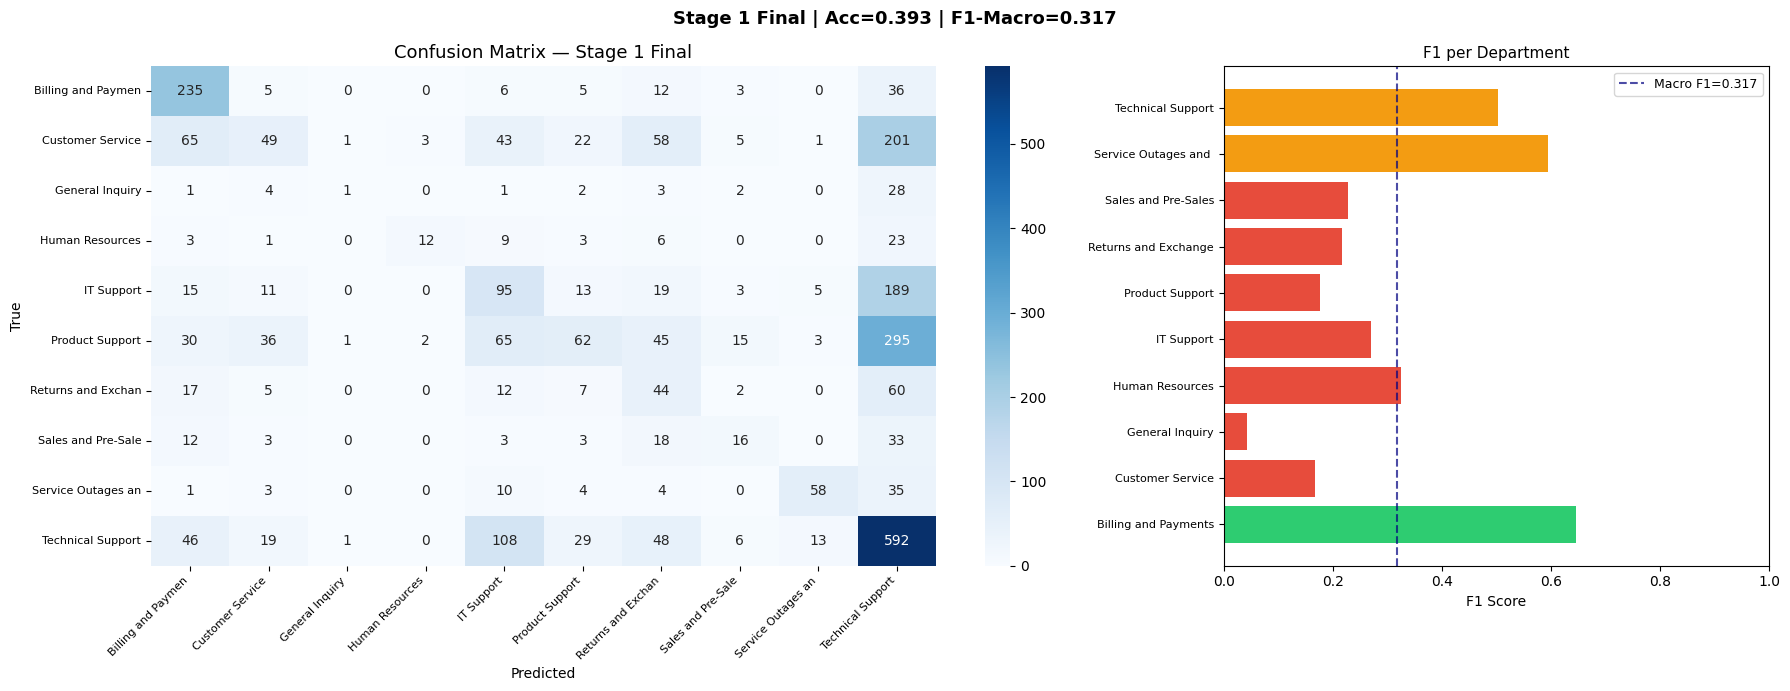


  STAGE 2/7 | LoRA_r16
  Samples: 3000 | Batches: 1500 | Max epochs: 3 | Patience: 2 (per-stage)
  Global best F1 so far: 0.3173
   Ep1 | Step  300/1500 | Loss:1.7714 | Acc:0.3767 | LR:1.70e-04
   Ep1 | Step  600/1500 | Loss:1.7177 | Acc:0.3875 | LR:1.68e-04
   Ep1 | Step  900/1500 | Loss:1.6830 | Acc:0.4050 | LR:1.66e-04
   Ep1 | Step 1200/1500 | Loss:1.6825 | Acc:0.4054 | LR:1.64e-04
   Ep1 | Step 1500/1500 | Loss:1.6748 | Acc:0.4067 | LR:1.62e-04

  ── Ep1 done | Loss=1.6748 | TrainAcc=0.4067
  Val S2/E1
  Accuracy    : 0.3673  (36.73%)
  F1 Macro    : 0.3250
  F1 Weighted : 0.3384

                                 precision    recall  f1-score   support

           Billing and Payments       0.69      0.71      0.70       302
               Customer Service       0.34      0.25      0.29       448
                General Inquiry       0.00      0.00      0.00        42
                Human Resources       0.70      0.28      0.40        57
                     IT Support       0.

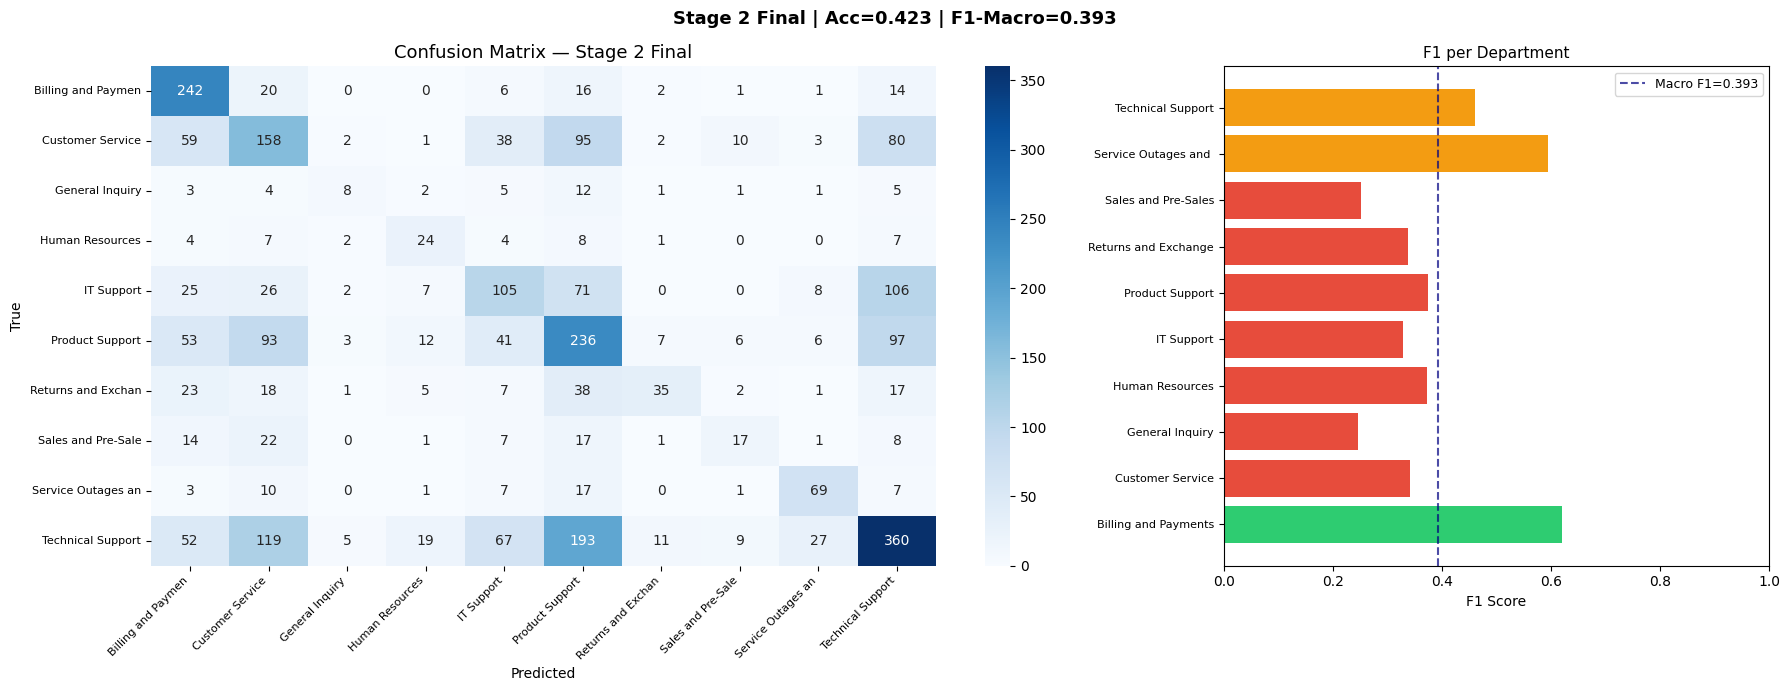


  STAGE 3/7 | LoRA_r16
  Samples: 3000 | Batches: 1500 | Max epochs: 3 | Patience: 2 (per-stage)
  Global best F1 so far: 0.3931
   Ep1 | Step  300/1500 | Loss:1.8576 | Acc:0.3933 | LR:1.41e-04
   Ep1 | Step  600/1500 | Loss:1.7303 | Acc:0.4192 | LR:1.39e-04
   Ep1 | Step  900/1500 | Loss:1.6760 | Acc:0.4144 | LR:1.37e-04
   Ep1 | Step 1200/1500 | Loss:1.6374 | Acc:0.4275 | LR:1.35e-04
   Ep1 | Step 1500/1500 | Loss:1.5909 | Acc:0.4457 | LR:1.33e-04

  ── Ep1 done | Loss=1.5909 | TrainAcc=0.4457
  Val S3/E1
  Accuracy    : 0.4951  (49.51%)
  F1 Macro    : 0.4565
  F1 Weighted : 0.4838

                                 precision    recall  f1-score   support

           Billing and Payments       0.64      0.82      0.72       302
               Customer Service       0.52      0.24      0.33       448
                General Inquiry       0.88      0.17      0.28        42
                Human Resources       0.90      0.32      0.47        57
                     IT Support       0.

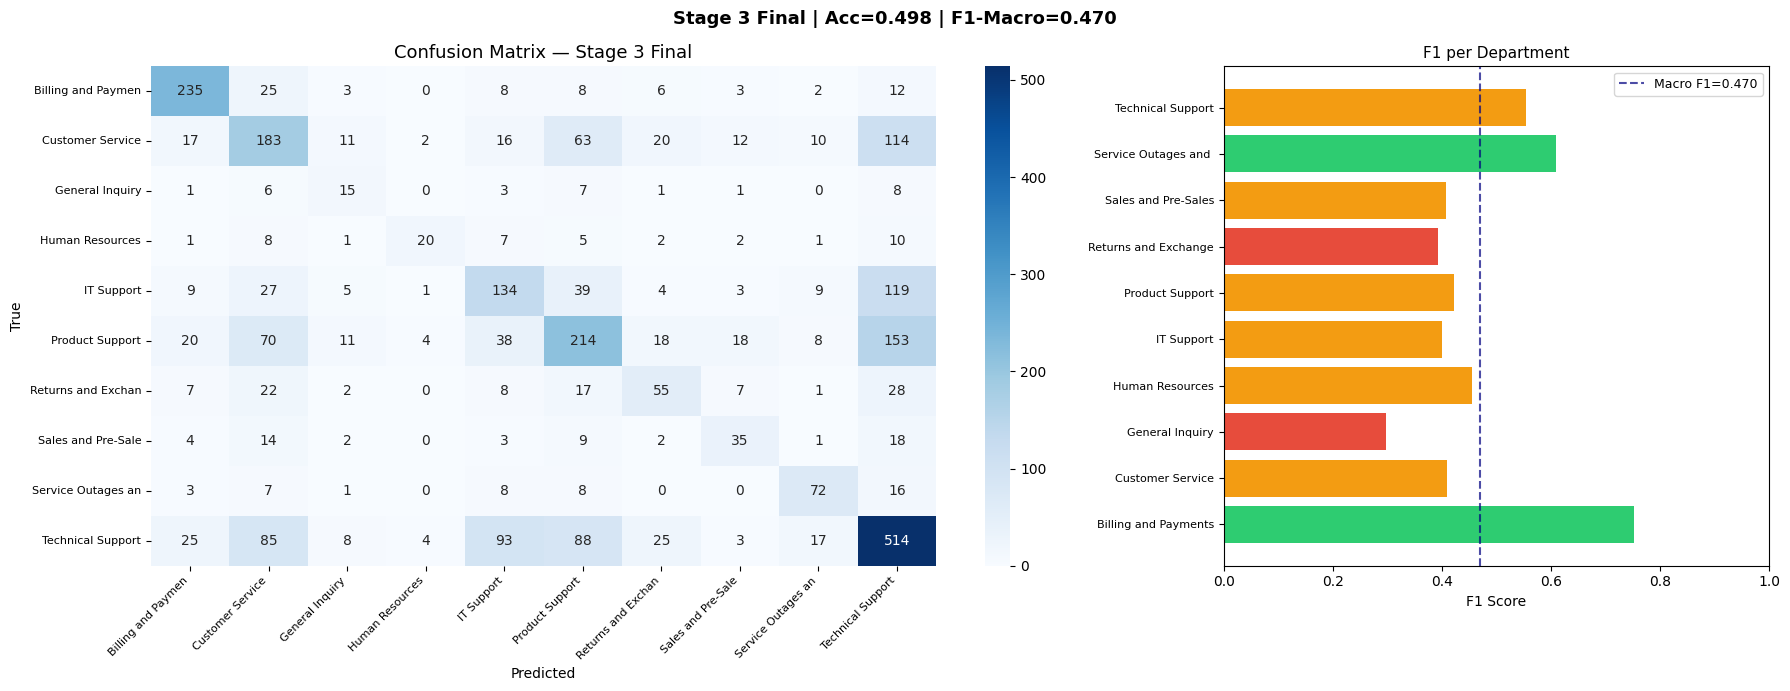


  STAGE 4/7 | LoRA_r16
  Samples: 3000 | Batches: 1500 | Max epochs: 3 | Patience: 2 (per-stage)
  Global best F1 so far: 0.4706
   Ep1 | Step  300/1500 | Loss:1.8850 | Acc:0.4917 | LR:1.12e-04
   Ep1 | Step  600/1500 | Loss:1.6719 | Acc:0.4800 | LR:1.11e-04
   Ep1 | Step  900/1500 | Loss:1.6028 | Acc:0.4928 | LR:1.09e-04
   Ep1 | Step 1200/1500 | Loss:1.5435 | Acc:0.5050 | LR:1.07e-04
   Ep1 | Step 1500/1500 | Loss:1.5065 | Acc:0.5103 | LR:1.05e-04

  ── Ep1 done | Loss=1.5065 | TrainAcc=0.5103
  Val S4/E1
  Accuracy    : 0.5265  (52.65%)
  F1 Macro    : 0.4694
  F1 Weighted : 0.5110

                                 precision    recall  f1-score   support

           Billing and Payments       0.92      0.74      0.82       302
               Customer Service       0.46      0.44      0.45       448
                General Inquiry       0.90      0.21      0.35        42
                Human Resources       1.00      0.30      0.46        57
                     IT Support       0.

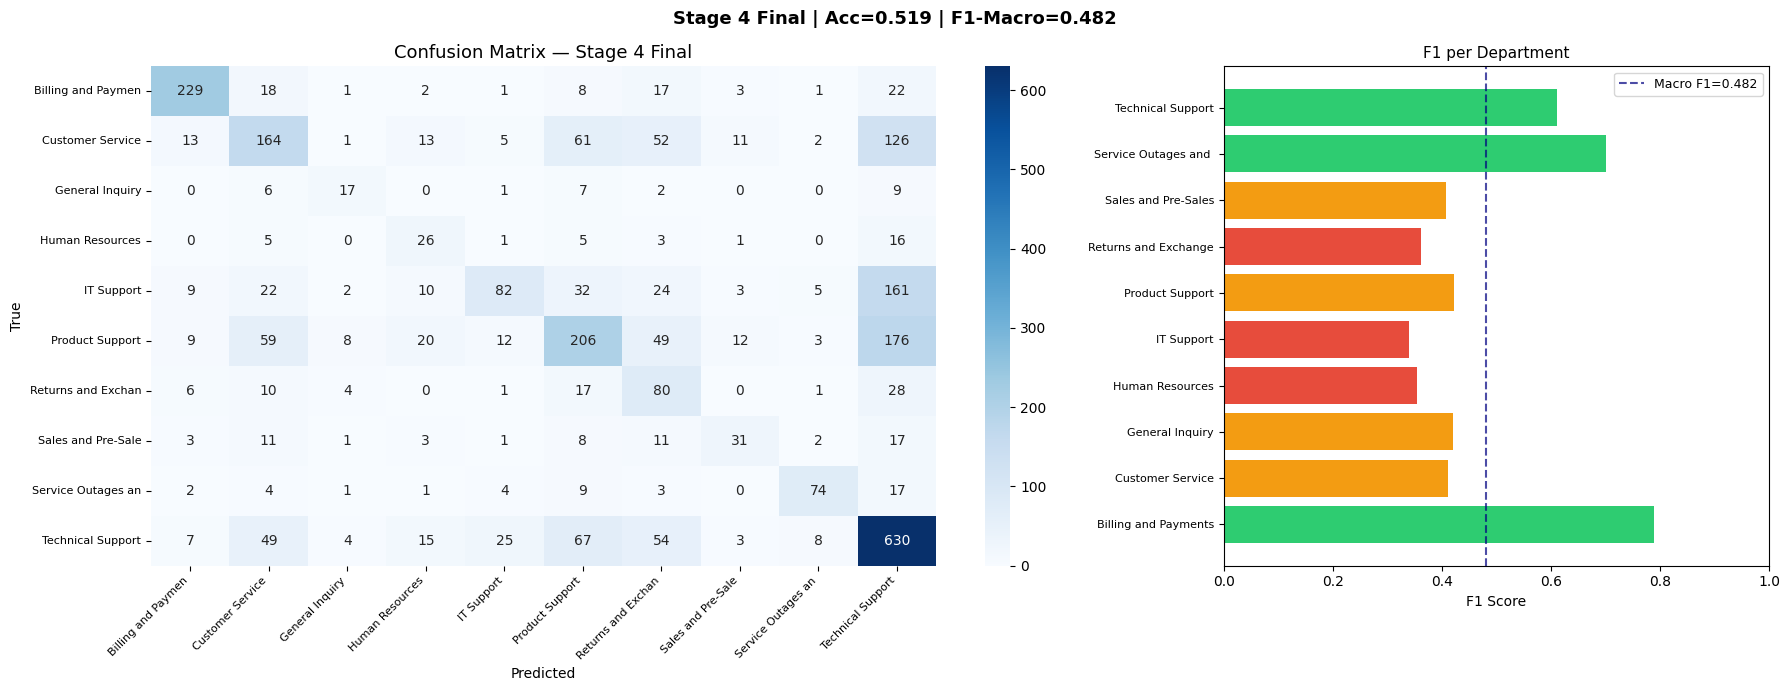


  STAGE 5/7 | LoRA_r16
  Samples: 3000 | Batches: 1500 | Max epochs: 3 | Patience: 2 (per-stage)
  Global best F1 so far: 0.4995
   Ep1 | Step  300/1500 | Loss:2.0063 | Acc:0.5133 | LR:8.39e-05
   Ep1 | Step  600/1500 | Loss:1.7185 | Acc:0.5075 | LR:8.20e-05
   Ep1 | Step  900/1500 | Loss:1.5987 | Acc:0.5228 | LR:8.00e-05
   Ep1 | Step 1200/1500 | Loss:1.5170 | Acc:0.5300 | LR:7.81e-05
   Ep1 | Step 1500/1500 | Loss:1.4738 | Acc:0.5340 | LR:7.62e-05

  ── Ep1 done | Loss=1.4738 | TrainAcc=0.5340
  Val S5/E1
  Accuracy    : 0.5639  (56.39%)
  F1 Macro    : 0.5352
  F1 Weighted : 0.5645

                                 precision    recall  f1-score   support

           Billing and Payments       0.91      0.77      0.83       302
               Customer Service       0.45      0.47      0.46       448
                General Inquiry       1.00      0.21      0.35        42
                Human Resources       1.00      0.33      0.50        57
                     IT Support       0.

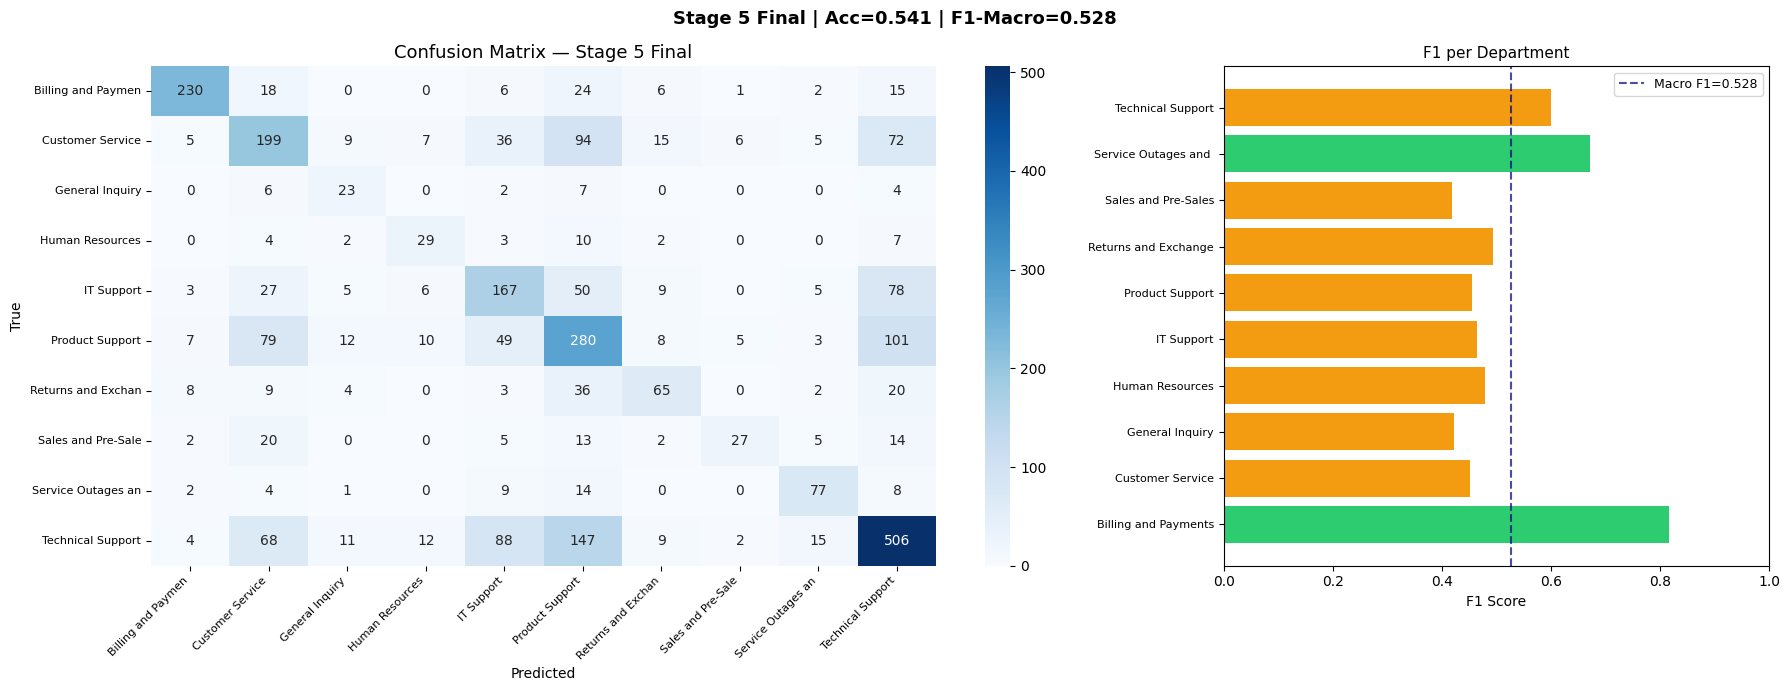


  STAGE 6/7 | LoRA_r16
  Samples: 3000 | Batches: 1500 | Max epochs: 3 | Patience: 2 (per-stage)
  Global best F1 so far: 0.5409
   Ep1 | Step  300/1500 | Loss:2.5578 | Acc:0.5550 | LR:5.53e-05
   Ep1 | Step  600/1500 | Loss:2.0505 | Acc:0.5492 | LR:5.34e-05
   Ep1 | Step  900/1500 | Loss:1.7721 | Acc:0.5606 | LR:5.15e-05
   Ep1 | Step 1200/1500 | Loss:1.6331 | Acc:0.5692 | LR:4.95e-05
   Ep1 | Step 1500/1500 | Loss:1.5381 | Acc:0.5770 | LR:4.76e-05

  ── Ep1 done | Loss=1.5381 | TrainAcc=0.5770
  Val S6/E1
  Accuracy    : 0.5990  (59.90%)
  F1 Macro    : 0.5873
  F1 Weighted : 0.5916

                                 precision    recall  f1-score   support

           Billing and Payments       0.92      0.75      0.83       302
               Customer Service       0.53      0.52      0.52       448
                General Inquiry       0.76      0.38      0.51        42
                Human Resources       0.93      0.47      0.63        57
                     IT Support       0.

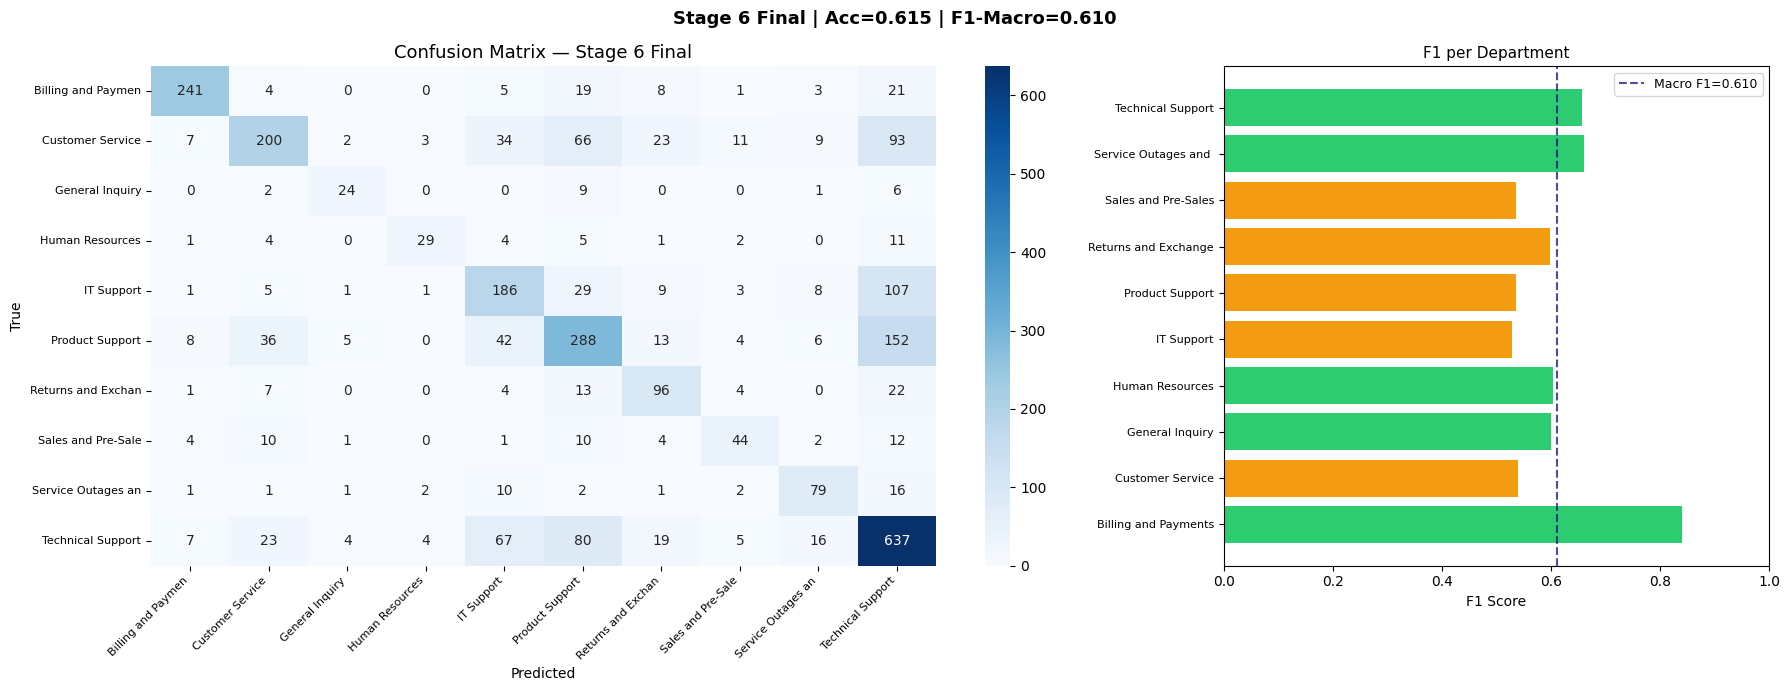


  STAGE 7/7 | LoRA_r16
  Samples: 3000 | Batches: 1500 | Max epochs: 3 | Patience: 2 (per-stage)
  Global best F1 so far: 0.6104
   Ep1 | Step  300/1500 | Loss:2.0344 | Acc:0.6417 | LR:2.67e-05
   Ep1 | Step  600/1500 | Loss:2.0312 | Acc:0.6233 | LR:2.48e-05
   Ep1 | Step  900/1500 | Loss:1.9017 | Acc:0.6178 | LR:2.29e-05
   Ep1 | Step 1200/1500 | Loss:1.7465 | Acc:0.6212 | LR:2.10e-05
   Ep1 | Step 1500/1500 | Loss:1.6285 | Acc:0.6213 | LR:1.90e-05

  ── Ep1 done | Loss=1.6285 | TrainAcc=0.6213
  Val S7/E1
  Accuracy    : 0.6519  (65.19%)
  F1 Macro    : 0.6577
  F1 Weighted : 0.6496

                                 precision    recall  f1-score   support

           Billing and Payments       0.85      0.82      0.84       302
               Customer Service       0.60      0.56      0.58       448
                General Inquiry       0.95      0.48      0.63        42
                Human Resources       0.86      0.63      0.73        57
                     IT Support       0.

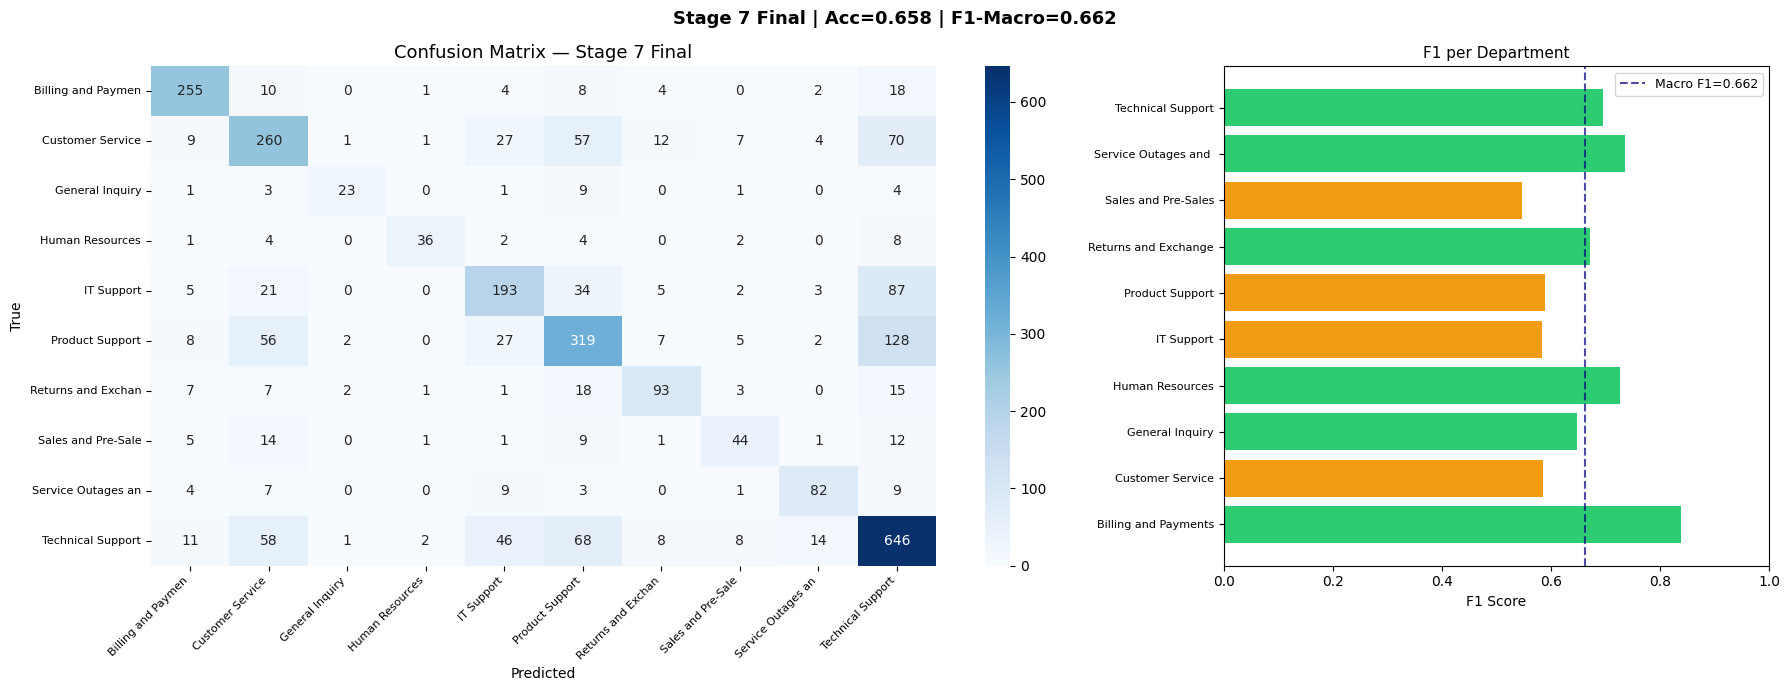


  TRAINING COMPLETE — LoRA_r16
  Best Val F1-Macro : 0.6674

Experiment summary:
  config  r  alpha  best_val_f1_macro  epochs_logged
LoRA_r16 16     32           0.667387             21


In [ ]:
# ══════════════════════════════════════════════════
# SELECT WHAT TO RUN
# Recommended order: r=8 first (paper best), then r=16, r=32
# ══════════════════════════════════════════════════
RUN_ALL_CONFIGS   = False    # True → run all configs sequentially
ACTIVE_CONFIG_IDX = 1        # 0=r8 | 1=r16 | 2=r32

configs_to_run = LORA_CONFIGS if RUN_ALL_CONFIGS else [LORA_CONFIGS[ACTIVE_CONFIG_IDX]]
all_summaries  = []

for cfg in configs_to_run:
    gc.collect()
    torch.cuda.empty_cache() if torch.cuda.is_available() else None

    lora_name = cfg['name']
    print()
    print('#' * 72)
    print(f'  Experiment: {lora_name}')
    print(f'  r={cfg["r"]} | alpha={cfg["alpha"]} (={cfg["alpha"]//cfg["r"]}r) | '
          f'lr={cfg["lr"]} | dropout={cfg["dropout"]}')
    print('#' * 72)

    model    = build_model(cfg)
    trainable = [p for p in model.parameters() if p.requires_grad]

    # ── FIX: AdamW8bit (paper Table 1: 8-bit optimizer)
    optimizer = bnb.optim.AdamW8bit(
        trainable,
        lr           = cfg['lr'],
        weight_decay = WEIGHT_DECAY,
    )

    # ── FIX: Single global scheduler (not per-stage)
    scheduler = build_global_scheduler(optimizer, stages)

    all_stage_metrics = []
    train_history     = []
    best_val_f1       = 0.0

    for stage_num in range(1, NUM_STAGES + 1):
        stage_metrics, best_val_f1, train_history = train_one_stage(
            model,
            stages[stage_num - 1],
            optimizer,
            scheduler,          # same scheduler passed through all stages
            stage_num,
            lora_name,
            best_val_f1,
            train_history=train_history,
        )
        all_stage_metrics.append({'stage': stage_num, **stage_metrics})

    # Save history
    summary_dir = os.path.join(CHECKPOINT_BASE, lora_name)
    os.makedirs(summary_dir, exist_ok=True)
    with open(os.path.join(summary_dir, 'training_history.json'), 'w') as f:
        json.dump(train_history, f, indent=2, default=str)
    with open(os.path.join(summary_dir, 'training_summary.json'), 'w') as f:
        json.dump(all_stage_metrics, f, indent=2, default=str)

    all_summaries.append({
        'config':             lora_name,
        'r':                  cfg['r'],
        'alpha':              cfg['alpha'],
        'best_val_f1_macro':  best_val_f1,
        'epochs_logged':      len(train_history),
    })

    print()
    print('=' * 72)
    print(f'  TRAINING COMPLETE — {lora_name}')
    print(f'  Best Val F1-Macro : {best_val_f1:.4f}')
    print('=' * 72)

print()
print('Experiment summary:')
print(pd.DataFrame(all_summaries).to_string(index=False))

new clean training


########################################################################
  Experiment: LoRA_r16
  r=16 | alpha=32 (=2r) | lr=0.0002 | dropout=0.05
########################################################################
==((====))==  Unsloth 2026.5.8: Fast Llama patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Unsloth: Dropout = 0 is supported for fast patching. You are using dropout = 0.05.
Unsloth will patch all other layers, except LoRA matrices, causing a performance hit.
Unsloth 2026.5.8 patched 28 layers with 0 QKV layers, 0 O layers and 0 MLP layers.


Loaded fresh rsLoRA adapters for training.
trainable params: 24,313,856 || all params: 3,237,063,680 || trainable%: 0.7511

✅ LlamaTicketClassifier ready
   Hidden size : 3072
   Head        : 3072 → 10  (single linear)
   rsLoRA      : enabled | alpha=32 = 2r
   Pooling     : last non-padding token
   Dropout     : 0.05 (LoRA)
  Global scheduler: 1848 total steps (88 per stage-epoch × 3 epochs × 7 stages)

  STAGE 1/7 | LoRA_r16
  Samples: 2800 | Batches: 1400 | Max epochs: 3 | Patience: 2 (per-stage)
  Global best F1 so far: 0.0000
   Ep1 | Step  300/1400 | Loss:2.9190 | Acc:0.2033 | LR:1.98e-04
   Ep1 | Step  600/1400 | Loss:2.4770 | Acc:0.2442 | LR:1.96e-04
   Ep1 | Step  900/1400 | Loss:2.3130 | Acc:0.2678 | LR:1.94e-04
   Ep1 | Step 1200/1400 | Loss:2.1870 | Acc:0.2908 | LR:1.92e-04
   Ep1 | Step 1400/1400 | Loss:2.1374 | Acc:0.3018 | LR:1.90e-04

  ── Ep1 done | Loss=2.1374 | TrainAcc=0.3018
  Val S1/E1
  Accuracy    : 0.3466  (34.66%)
  F1 Macro    : 0.1867
  F1 Weighted : 0.28

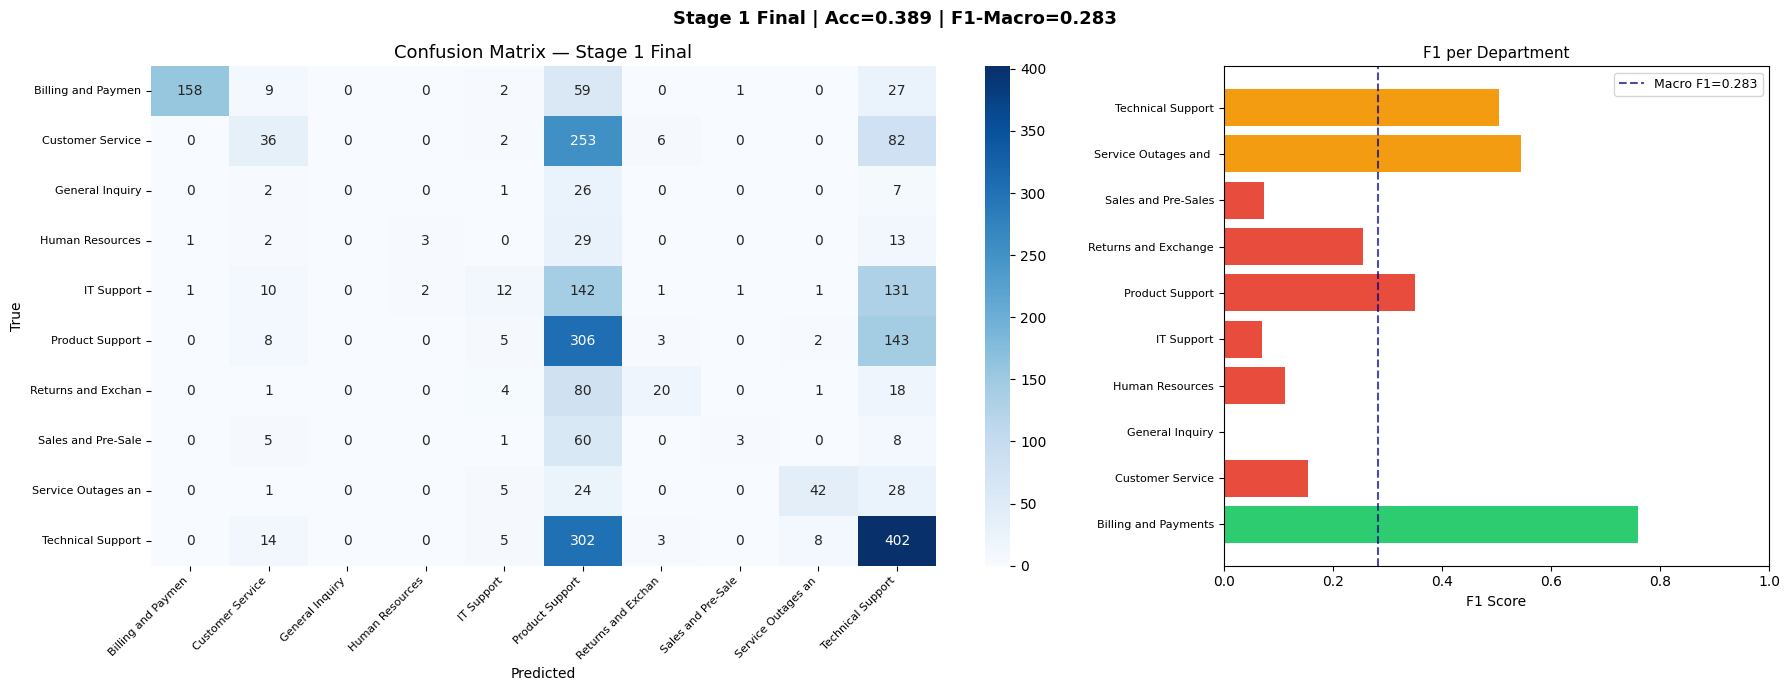


  STAGE 2/7 | LoRA_r16
  Samples: 2800 | Batches: 1400 | Max epochs: 3 | Patience: 2 (per-stage)
  Global best F1 so far: 0.2826
   Ep1 | Step  300/1400 | Loss:1.7244 | Acc:0.3983 | LR:1.69e-04
   Ep1 | Step  600/1400 | Loss:1.7148 | Acc:0.3825 | LR:1.67e-04
   Ep1 | Step  900/1400 | Loss:1.7056 | Acc:0.3894 | LR:1.65e-04
   Ep1 | Step 1200/1400 | Loss:1.6987 | Acc:0.3929 | LR:1.63e-04
   Ep1 | Step 1400/1400 | Loss:1.6933 | Acc:0.3932 | LR:1.62e-04

  ── Ep1 done | Loss=1.6933 | TrainAcc=0.3932
  Val S2/E1
  Accuracy    : 0.4282  (42.82%)
  F1 Macro    : 0.3153
  F1 Weighted : 0.3841

                                 precision    recall  f1-score   support

           Billing and Payments       0.83      0.71      0.77       256
               Customer Service       0.28      0.47      0.35       379
                General Inquiry       0.00      0.00      0.00        36
                Human Resources       0.79      0.23      0.35        48
                     IT Support       0.

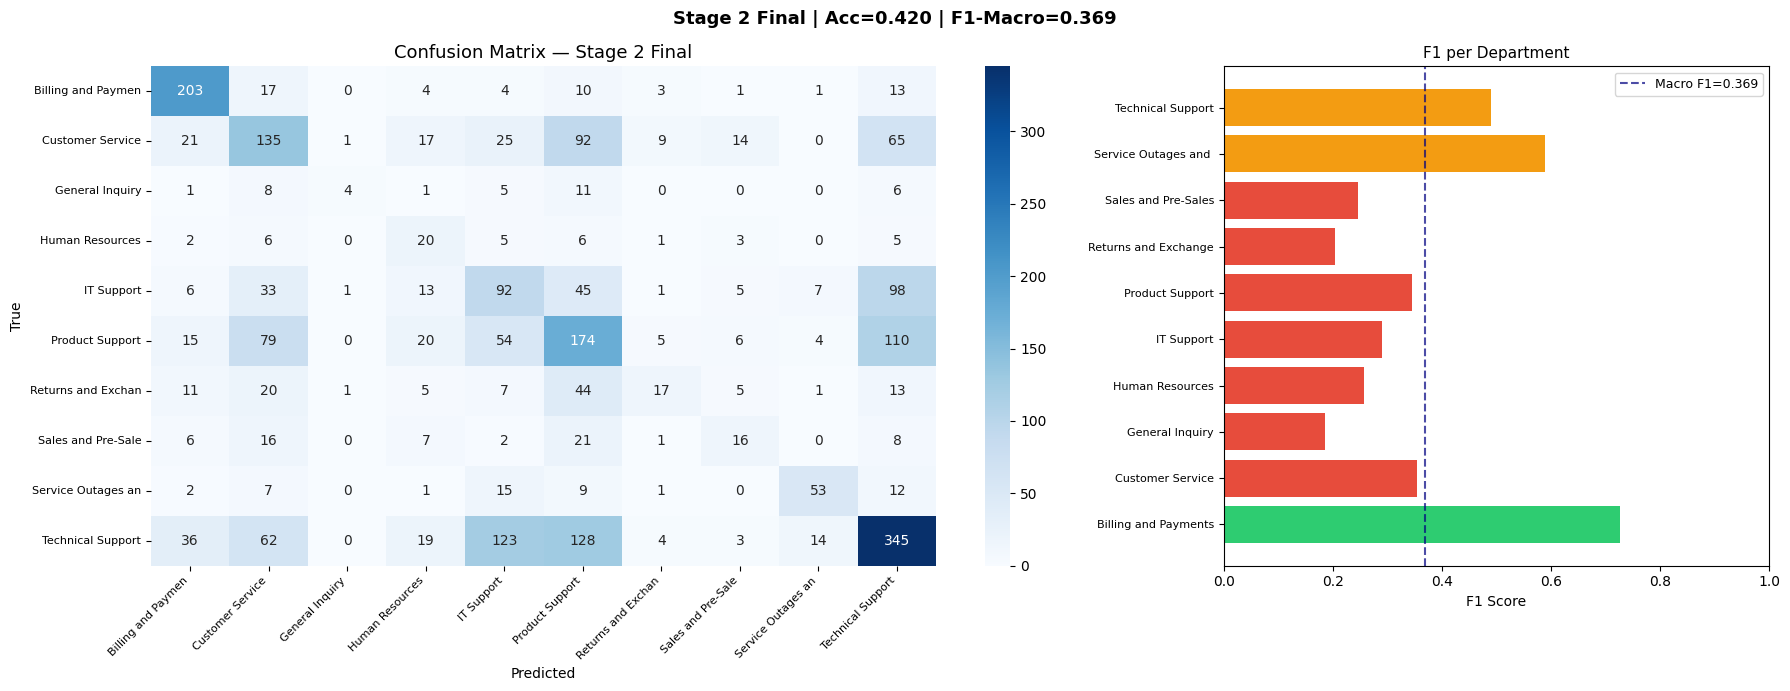


  STAGE 3/7 | LoRA_r16
  Samples: 2800 | Batches: 1400 | Max epochs: 3 | Patience: 2 (per-stage)
  Global best F1 so far: 0.3691
   Ep1 | Step  300/1400 | Loss:1.9425 | Acc:0.3967 | LR:1.41e-04
   Ep1 | Step  600/1400 | Loss:1.7841 | Acc:0.4042 | LR:1.39e-04
   Ep1 | Step  900/1400 | Loss:1.7390 | Acc:0.4033 | LR:1.37e-04
   Ep1 | Step 1200/1400 | Loss:1.6969 | Acc:0.4121 | LR:1.35e-04
   Ep1 | Step 1400/1400 | Loss:1.7092 | Acc:0.3964 | LR:1.33e-04

  ── Ep1 done | Loss=1.7092 | TrainAcc=0.3964
  Val S3/E1
  Accuracy    : 0.4465  (44.65%)
  F1 Macro    : 0.3409
  F1 Weighted : 0.3882

                                 precision    recall  f1-score   support

           Billing and Payments       0.98      0.68      0.80       256
               Customer Service       0.32      0.45      0.38       379
                General Inquiry       0.00      0.00      0.00        36
                Human Resources       0.92      0.23      0.37        48
                     IT Support       0.

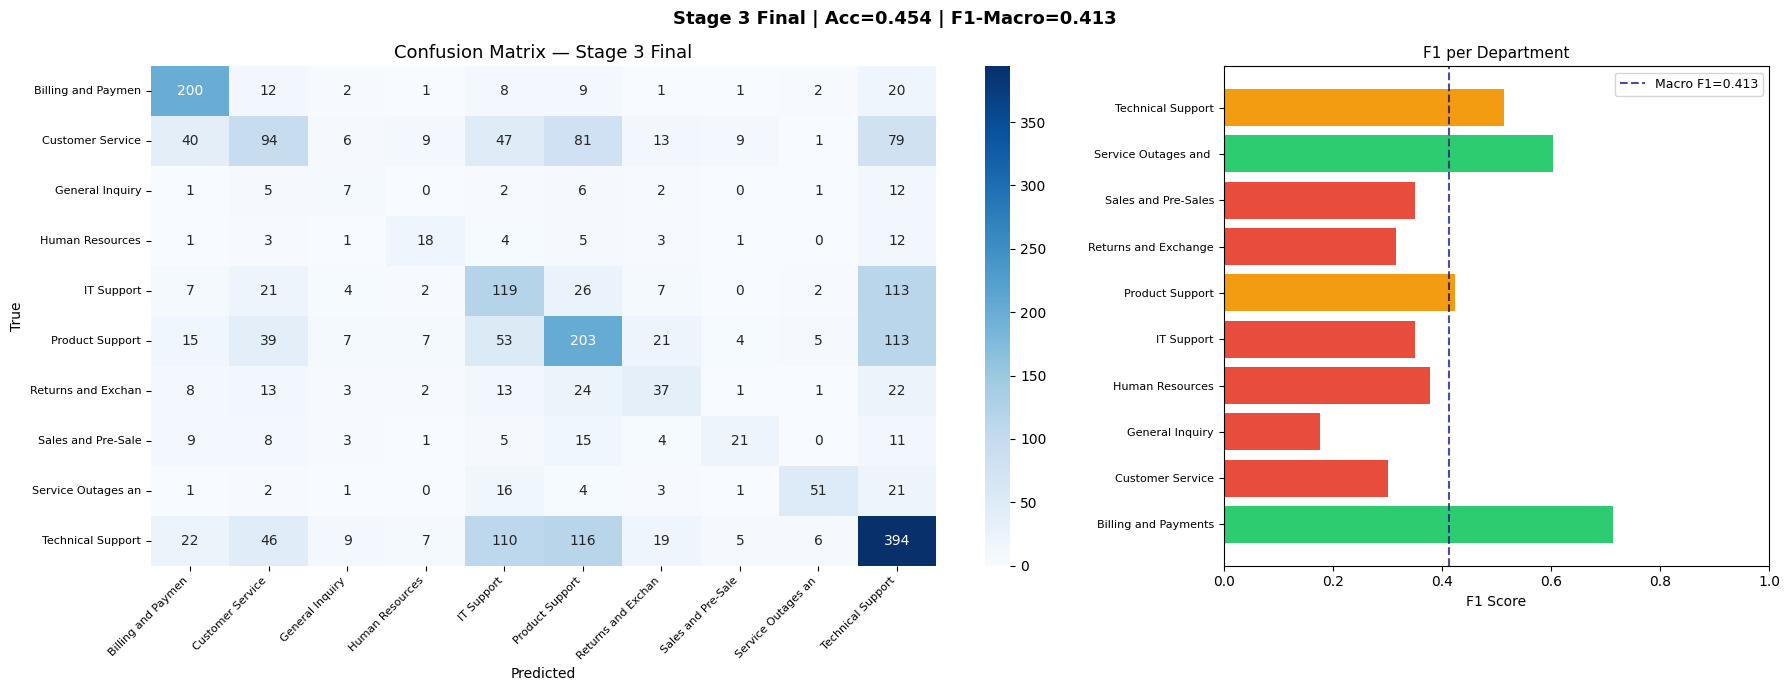


  STAGE 4/7 | LoRA_r16
  Samples: 2800 | Batches: 1400 | Max epochs: 3 | Patience: 2 (per-stage)
  Global best F1 so far: 0.4133
   Ep1 | Step  300/1400 | Loss:1.9753 | Acc:0.4217 | LR:1.12e-04
   Ep1 | Step  600/1400 | Loss:1.7966 | Acc:0.4258 | LR:1.10e-04
   Ep1 | Step  900/1400 | Loss:1.7221 | Acc:0.4344 | LR:1.08e-04
   Ep1 | Step 1200/1400 | Loss:1.6694 | Acc:0.4375 | LR:1.06e-04
   Ep1 | Step 1400/1400 | Loss:1.6427 | Acc:0.4432 | LR:1.05e-04

  ── Ep1 done | Loss=1.6427 | TrainAcc=0.4432
  Val S4/E1
  Accuracy    : 0.4921  (49.21%)
  F1 Macro    : 0.4110
  F1 Weighted : 0.4763

                                 precision    recall  f1-score   support

           Billing and Payments       0.90      0.75      0.82       256
               Customer Service       0.44      0.31      0.36       379
                General Inquiry       0.00      0.00      0.00        36
                Human Resources       0.86      0.25      0.39        48
                     IT Support       0.

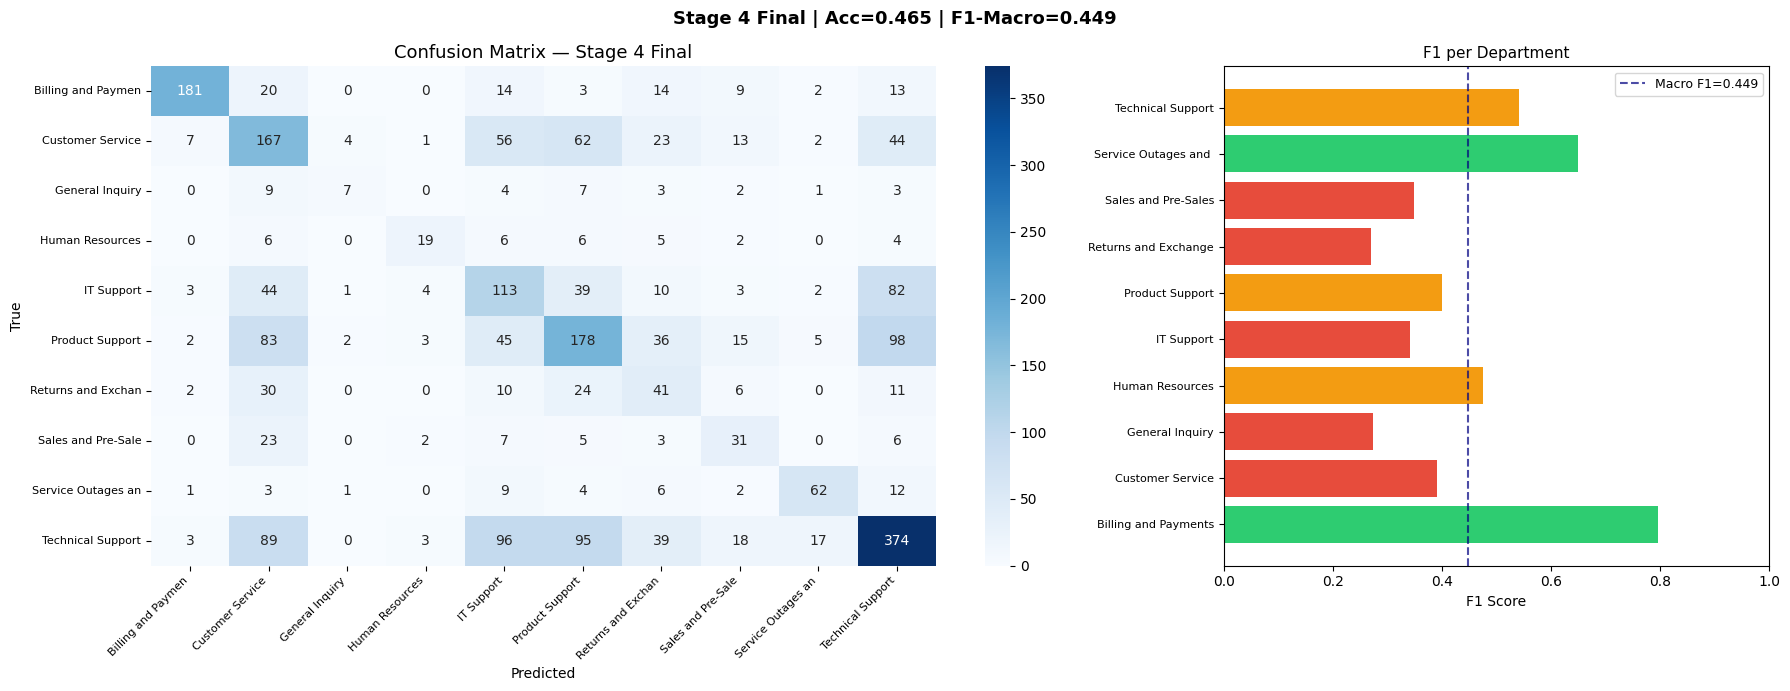


  STAGE 5/7 | LoRA_r16
  Samples: 2800 | Batches: 1400 | Max epochs: 3 | Patience: 2 (per-stage)
  Global best F1 so far: 0.4543
   Ep1 | Step  300/1400 | Loss:2.2899 | Acc:0.5033 | LR:8.38e-05
   Ep1 | Step  600/1400 | Loss:1.9041 | Acc:0.4833 | LR:8.17e-05
   Ep1 | Step  900/1400 | Loss:1.7978 | Acc:0.4644 | LR:7.97e-05
   Ep1 | Step 1200/1400 | Loss:1.7113 | Acc:0.4721 | LR:7.76e-05
   Ep1 | Step 1400/1400 | Loss:1.6708 | Acc:0.4739 | LR:7.62e-05

  ── Ep1 done | Loss=1.6708 | TrainAcc=0.4739
  Val S5/E1
  Accuracy    : 0.5004  (50.04%)
  F1 Macro    : 0.4405
  F1 Weighted : 0.4845

                                 precision    recall  f1-score   support

           Billing and Payments       0.91      0.75      0.82       256
               Customer Service       0.33      0.69      0.45       379
                General Inquiry       1.00      0.03      0.05        36
                Human Resources       0.82      0.38      0.51        48
                     IT Support       0.

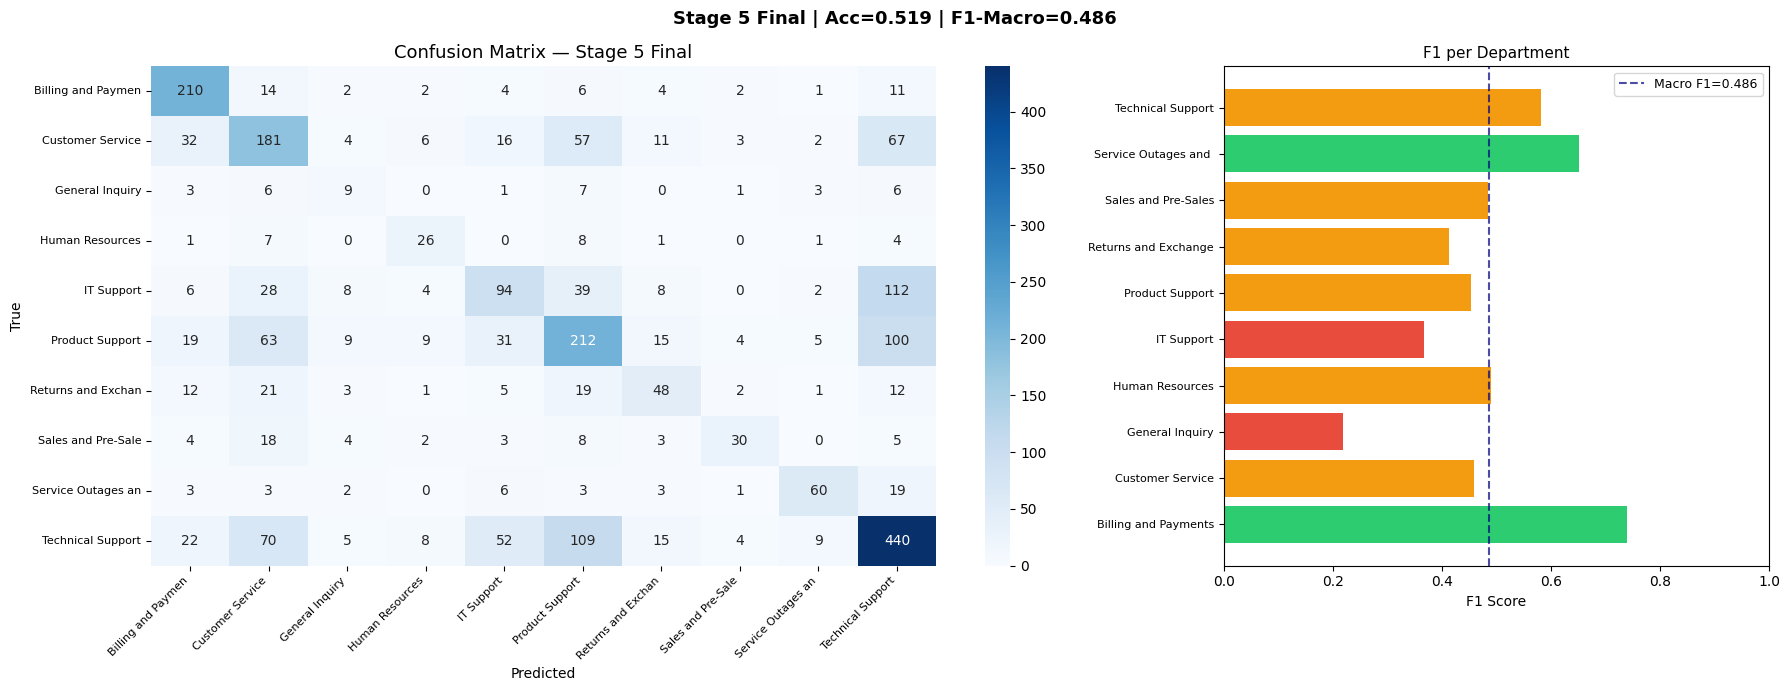


  STAGE 6/7 | LoRA_r16
  Samples: 2800 | Batches: 1400 | Max epochs: 3 | Patience: 2 (per-stage)
  Global best F1 so far: 0.4860
   Ep1 | Step  300/1400 | Loss:2.4720 | Acc:0.5167 | LR:5.52e-05
   Ep1 | Step  600/1400 | Loss:2.0859 | Acc:0.4908 | LR:5.31e-05
   Ep1 | Step  900/1400 | Loss:1.8670 | Acc:0.4939 | LR:5.11e-05
   Ep1 | Step 1200/1400 | Loss:1.7520 | Acc:0.5000 | LR:4.90e-05
   Ep1 | Step 1400/1400 | Loss:1.6854 | Acc:0.5086 | LR:4.76e-05

  ── Ep1 done | Loss=1.6854 | TrainAcc=0.5086
  Val S6/E1
  Accuracy    : 0.5428  (54.28%)
  F1 Macro    : 0.5013
  F1 Weighted : 0.5273

                                 precision    recall  f1-score   support

           Billing and Payments       0.79      0.82      0.81       256
               Customer Service       0.51      0.41      0.46       379
                General Inquiry       1.00      0.08      0.15        36
                Human Resources       0.73      0.50      0.59        48
                     IT Support       0.

In [ ]:
# ══════════════════════════════════════════════════
# SELECT WHAT TO RUN
# Recommended order: r=8 first (paper best), then r=16, r=32
# ══════════════════════════════════════════════════
RUN_ALL_CONFIGS   = False    # True → run all configs sequentially
ACTIVE_CONFIG_IDX = 1        # 0=r8 | 1=r16 | 2=r32

configs_to_run = LORA_CONFIGS if RUN_ALL_CONFIGS else [LORA_CONFIGS[ACTIVE_CONFIG_IDX]]
all_summaries  = []

for cfg in configs_to_run:
    gc.collect()
    torch.cuda.empty_cache() if torch.cuda.is_available() else None

    lora_name = cfg['name']
    print()
    print('#' * 72)
    print(f'  Experiment: {lora_name}')
    print(f'  r={cfg["r"]} | alpha={cfg["alpha"]} (={cfg["alpha"]//cfg["r"]}r) | '
          f'lr={cfg["lr"]} | dropout={cfg["dropout"]}')
    print('#' * 72)

    model    = build_model(cfg)
    trainable = [p for p in model.parameters() if p.requires_grad]

    # ── FIX: AdamW8bit (paper Table 1: 8-bit optimizer)
    optimizer = bnb.optim.AdamW8bit(
        trainable,
        lr           = cfg['lr'],
        weight_decay = WEIGHT_DECAY,
    )

    # ── FIX: Single global scheduler (not per-stage)
    scheduler = build_global_scheduler(optimizer, stages)

    all_stage_metrics = []
    train_history     = []
    best_val_f1       = 0.0

    for stage_num in range(1, NUM_STAGES + 1):
        stage_metrics, best_val_f1, train_history = train_one_stage(
            model,
            stages[stage_num - 1],
            optimizer,
            scheduler,          # same scheduler passed through all stages
            stage_num,
            lora_name,
            best_val_f1,
            train_history=train_history,
        )
        all_stage_metrics.append({'stage': stage_num, **stage_metrics})

    # Save history
    summary_dir = os.path.join(CHECKPOINT_BASE, lora_name)
    os.makedirs(summary_dir, exist_ok=True)
    with open(os.path.join(summary_dir, 'training_history.json'), 'w') as f:
        json.dump(train_history, f, indent=2, default=str)
    with open(os.path.join(summary_dir, 'training_summary.json'), 'w') as f:
        json.dump(all_stage_metrics, f, indent=2, default=str)

    all_summaries.append({
        'config':             lora_name,
        'r':                  cfg['r'],
        'alpha':              cfg['alpha'],
        'best_val_f1_macro':  best_val_f1,
        'epochs_logged':      len(train_history),
    })

    print()
    print('=' * 72)
    print(f'  TRAINING COMPLETE — {lora_name}')
    print(f'  Best Val F1-Macro : {best_val_f1:.4f}')
    print('=' * 72)

print()
print('Experiment summary:')
print(pd.DataFrame(all_summaries).to_string(index=False))

==((====))==  Unsloth 2026.5.8: Fast Llama patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Unsloth: Dropout = 0 is supported for fast patching. You are using dropout = 0.05.
Unsloth will patch all other layers, except LoRA matrices, causing a performance hit.
Unsloth 2026.5.8 patched 28 layers with 0 QKV layers, 0 O layers and 0 MLP layers.


Loaded fresh rsLoRA adapters for training.
trainable params: 24,313,856 || all params: 3,237,063,680 || trainable%: 0.7511

✅ LlamaTicketClassifier ready
   Hidden size : 3072
   Head        : 3072 → 10  (single linear)
   rsLoRA      : enabled | alpha=32 = 2r
   Pooling     : last non-padding token
   Dropout     : 0.05 (LoRA)
✅ Loaded LoRA weights from /content/drive/MyDrive/llama32-ticket-cls-v2/LoRA_r16/LAST/lora_adapters
✅ Loaded classifier head from /content/drive/MyDrive/llama32-ticket-cls-v2/LoRA_r16/LAST
  Global scheduler: 1848 total steps (88 per stage-epoch × 3 epochs × 7 stages)
  ✅ Loaded state: stage=6 ep=3 best_f1=0.5260

▶ Resuming: stage 7, epoch 1 | best_f1=0.5260


  STAGE 7/7 | LoRA_r16
  Samples: 2800 | Batches: 1400 | Max epochs: 3 | Patience: 2 (per-stage)
  Global best F1 so far: 0.5260
   Ep1 | Step  300/1400 | Loss:2.5075 | Acc:0.5400 | LR:2.66e-05
   Ep1 | Step  600/1400 | Loss:2.2252 | Acc:0.5617 | LR:2.46e-05
   Ep1 | Step  900/1400 | Loss:2.0435 | Acc:0.5

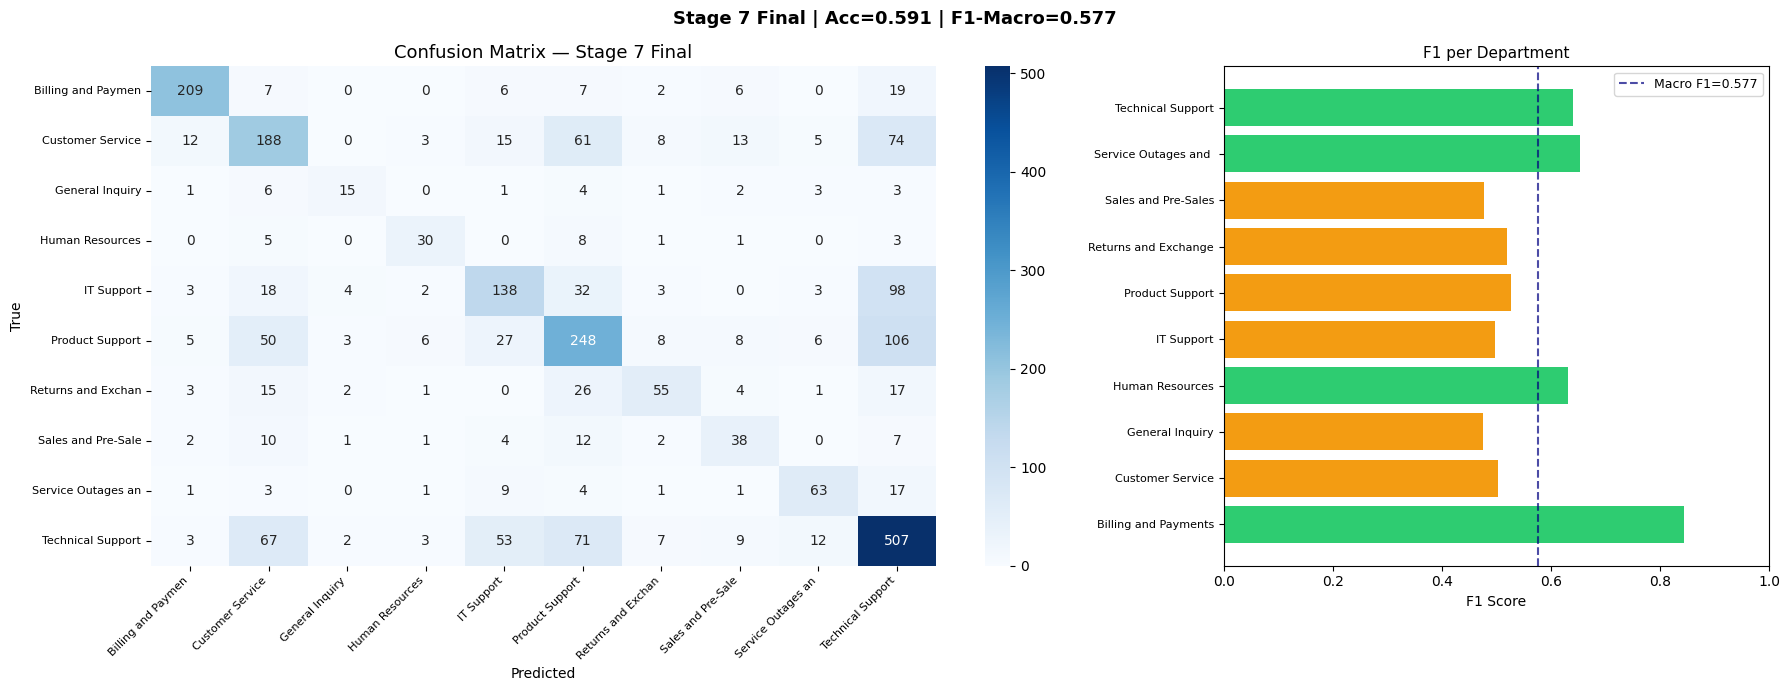


✅ RESUME COMPLETE — best Val F1-Macro: 0.5770


In [ ]:



# ============================================================
# RESUME (T4-safe): build FRESH model + load saved LoRA weights
# ============================================================
import gc, os, torch
from peft import set_peft_model_state_dict
from safetensors.torch import load_file
gc.collect(); torch.cuda.empty_cache() if torch.cuda.is_available() else None

RUN_ALL_CONFIGS   = False    # True → run all configs sequentially
ACTIVE_CONFIG_IDX = 1        # 0=r8 | 1=r16 | 2=r32


cfg        = LORA_CONFIGS[ACTIVE_CONFIG_IDX]
lora_name  = cfg['name']
RESUME_TAG = 'LAST'

# 1) FRESH build → يطبع "Loaded fresh rsLoRA adapters for training." (مش "Loaded adapters from")
model = build_model(cfg)

# 2) حمّل أوزان الـ LoRA المحفوظة جوه الموديل الـ fresh
adapter_path = adapter_dir(lora_name, RESUME_TAG)
sf = os.path.join(adapter_path, 'adapter_model.safetensors')
bn = os.path.join(adapter_path, 'adapter_model.bin')
lora_sd = load_file(sf) if os.path.exists(sf) else torch.load(bn, map_location='cpu')
res = set_peft_model_state_dict(model.backbone, lora_sd)
print(f'✅ Loaded LoRA weights from {adapter_path}')

# 3) الـ classifier head
load_classifier_head(model, lora_name, tag=RESUME_TAG)

# 4) optimizer + scheduler + state
trainable = [p for p in model.parameters() if p.requires_grad]
optimizer = bnb.optim.AdamW8bit(trainable, lr=cfg['lr'], weight_decay=WEIGHT_DECAY)
scheduler = build_global_scheduler(optimizer, stages)
state = load_checkpoint_state(optimizer, scheduler, lora_name, tag=RESUME_TAG)

best_val_f1   = state['best_val_f1']
train_history = state['train_history']
last_stage    = state['stage']
last_epoch    = state['epoch']
resume_stage, start_epoch = (last_stage + 1, 1) if last_epoch >= MAX_EPOCHS else (last_stage, last_epoch + 1)
print(f'\n▶ Resuming: stage {resume_stage}, epoch {start_epoch} | best_f1={best_val_f1:.4f}\n')

# 5) كمّل
if resume_stage > NUM_STAGES:
    print('✅ All stages already completed.')
else:
    for stage_num in range(resume_stage, NUM_STAGES + 1):
        _, best_val_f1, train_history = train_one_stage(
            model, stages[stage_num - 1], optimizer, scheduler,
            stage_num, lora_name, best_val_f1,
            start_epoch=(start_epoch if stage_num == resume_stage else 1),
            train_history=train_history,
        )
    print(f'\n✅ RESUME COMPLETE — best Val F1-Macro: {best_val_f1:.4f}')

new clean test

==((====))==  Unsloth 2026.5.8: Fast Llama patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Loaded adapters from: /content/drive/MyDrive/llama32-ticket-cls-v2/LoRA_r16/BEST/lora_adapters
trainable params: 0 || all params: 3,237,063,680 || trainable%: 0.0000

✅ LlamaTicketClassifier ready
   Hidden size : 3072
   Head        : 3072 → 10  (single linear)
   rsLoRA      : enabled | alpha=32 = 2r
   Pooling     : last non-padding token
   Dropout     : 0.05 (LoRA)
✅ Loaded classifier head from /content/drive/MyDrive/llama32-ticket-cls-v2/LoRA_r16/BEST
✅ Loaded BEST checkpoint for LoRA_r16
  VAL CHECK — LoRA_r16
  Accuracy    : 0.5912  (5

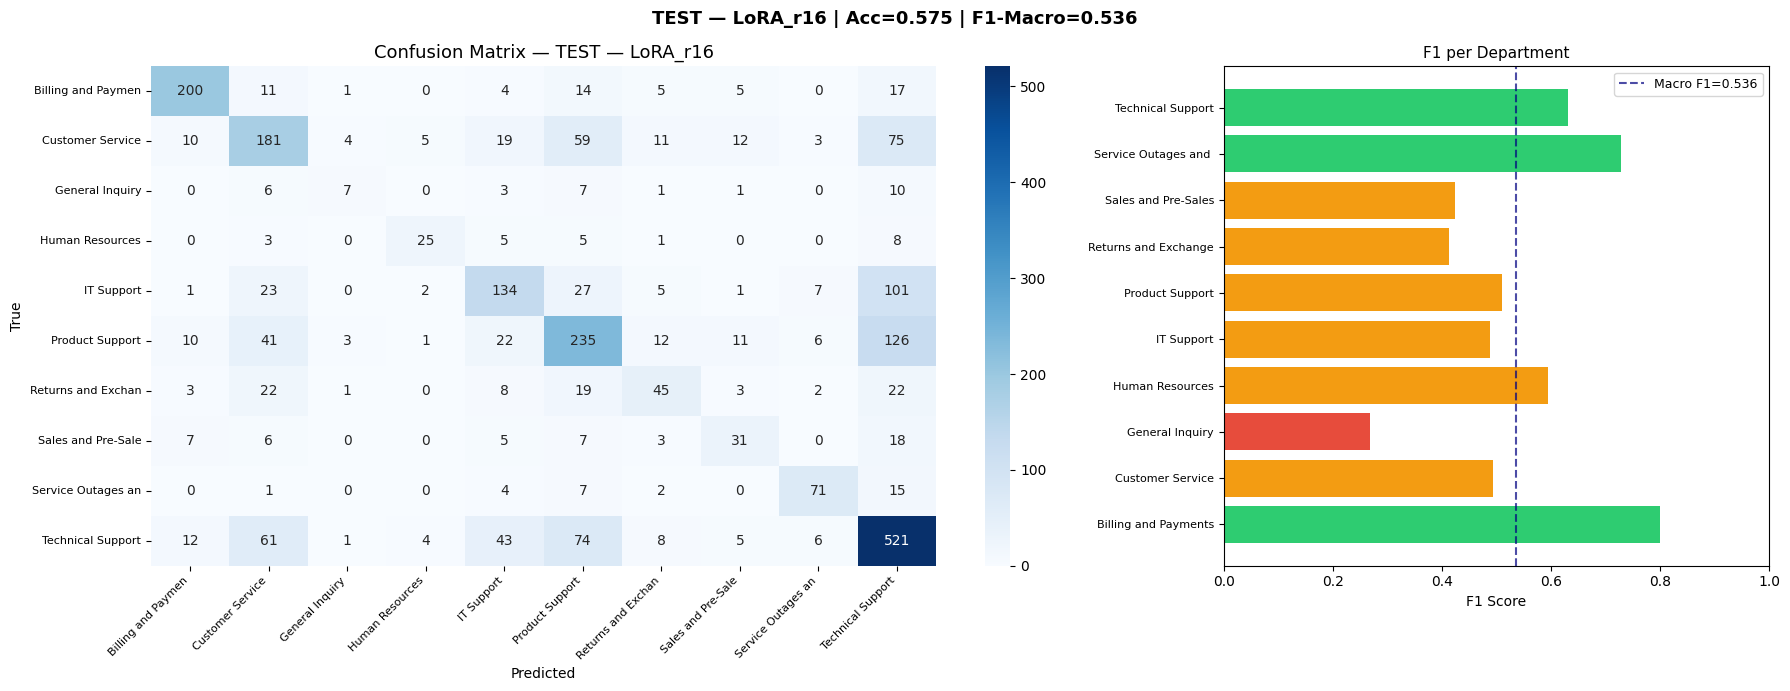


  FINAL TEST RESULTS — LoRA_r16  (deduplicated corpus)
  Test size   : 2523
  Accuracy    : 0.5747
  Macro F1    : 0.5355
  Weighted F1 : 0.5697


In [ ]:
import os, gc, torch
gc.collect()
torch.cuda.empty_cache() if torch.cuda.is_available() else None

LORA_NAME = 'LoRA_r16'
TAG = 'BEST'

model = build_model(
    next(c for c in LORA_CONFIGS if c['name'] == LORA_NAME),
    adapter_path=adapter_dir(LORA_NAME, TAG),
    is_trainable=False,
)
loaded = load_classifier_head(model, LORA_NAME, tag=TAG)

if loaded:
    model.eval()
    print(f'✅ Loaded {TAG} checkpoint for {LORA_NAME}')

    # Val check (just to confirm the checkpoint loaded — no hardcoded gate)
    val_m = evaluate(model, val_loader,
                     split_name=f'VAL CHECK — {LORA_NAME}', show_plots=False)
    print(f'Val F1 Macro: {val_m["f1_macro"]:.4f}')

    # Test evaluation (test set is already clean — corpus was deduplicated before split)
    test_m = evaluate(model, test_loader,
                      split_name=f'TEST — {LORA_NAME}', show_plots=True)

    print('\n' + '=' * 60)
    print(f'  FINAL TEST RESULTS — {LORA_NAME}  (deduplicated corpus)')
    print('=' * 60)
    print(f'  Test size   : {len(test_df)}')
    print(f'  Accuracy    : {test_m["accuracy"]:.4f}')
    print(f'  Macro F1    : {test_m["f1_macro"]:.4f}')
    print(f'  Weighted F1 : {test_m["f1_weighted"]:.4f}')
else:
    print('❌ Failed to load BEST checkpoint')

duration 7 hours

old **test** with data leakage

==((====))==  Unsloth 2026.5.2: Fast Llama patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Loaded adapters from: /content/drive/MyDrive/llama32-ticket-cls-v2/LoRA_r16/BEST/lora_adapters
trainable params: 0 || all params: 3,237,063,680 || trainable%: 0.0000

✅ LlamaTicketClassifier ready
   Hidden size : 3072
   Head        : 3072 → 10  (single linear)
   rsLoRA      : enabled | alpha=32 = 2r
   Pooling     : last non-padding token
   Dropout     : 0.05 (LoRA)
✅ Loaded classifier head from /content/drive/MyDrive/llama32-ticket-cls-v2/LoRA_r16/BEST
✅ Model loaded from BEST checkpoint
  VAL CHECK — LoRA_r16
  Accuracy    : 0.6583  (65.

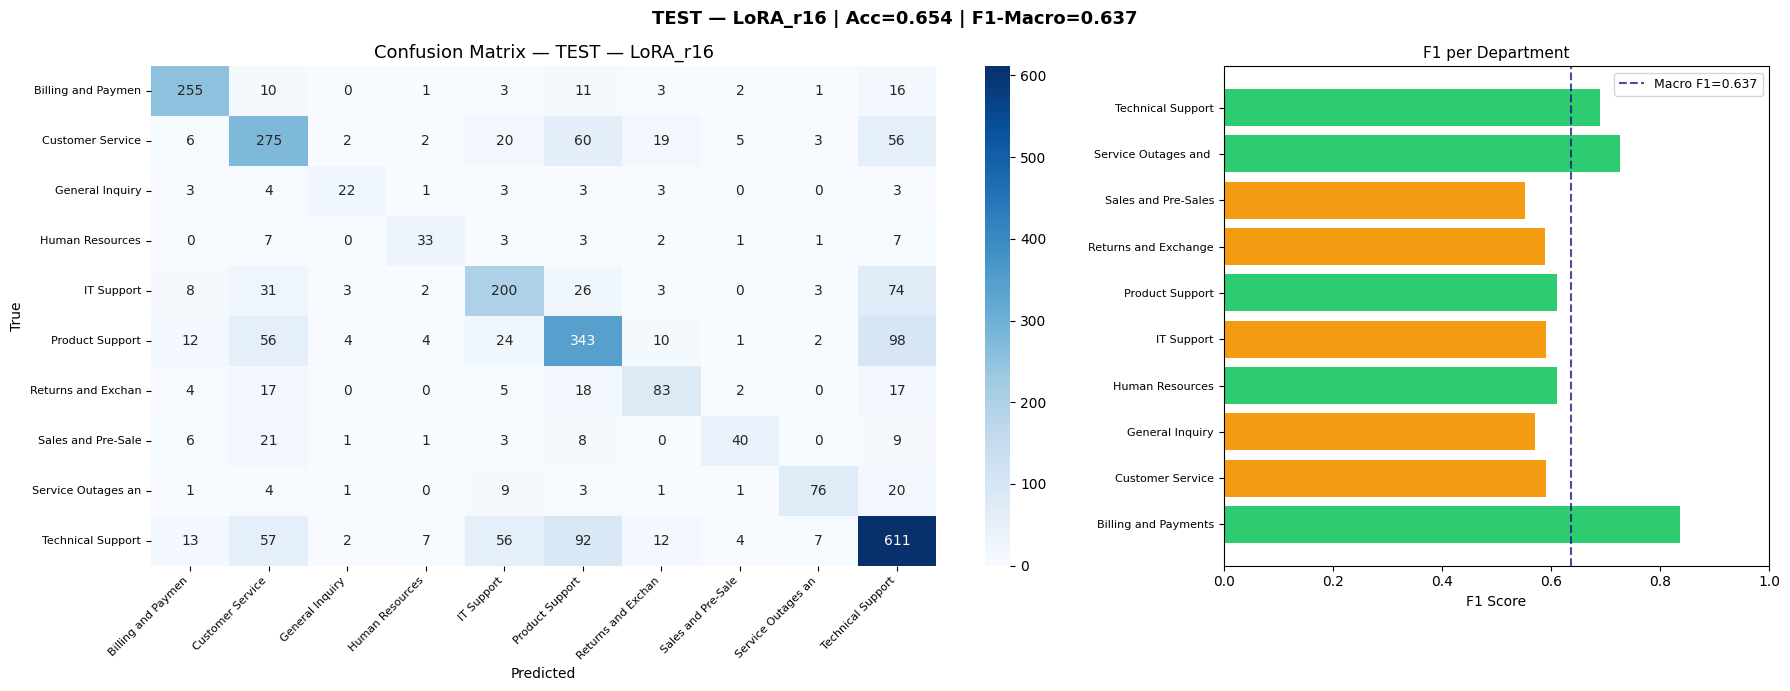


Final Test F1 Macro: 0.6371


In [ ]:
import os, gc, torch

gc.collect()
torch.cuda.empty_cache() if torch.cuda.is_available() else None

LORA_NAME = 'LoRA_r16'
TAG = 'BEST'

# Load model from BEST checkpoint
model = build_model(
    next(c for c in LORA_CONFIGS if c['name'] == LORA_NAME),
    adapter_path=adapter_dir(LORA_NAME, TAG),
    is_trainable=False
)
loaded = load_classifier_head(model, LORA_NAME, tag=TAG)

if loaded:
    model.eval()
    print(f'✅ Model loaded from {TAG} checkpoint')

    # Val check أول عشان نتأكد
    val_m = evaluate(model, val_loader,
                     split_name=f'VAL CHECK — {LORA_NAME}',
                     show_plots=False)
    print(f'Val F1 Macro: {val_m["f1_macro"]:.4f}')
    print(f'Expected:     0.6674')

    # لو الأرقام متطابقة ← شغّل test
    if abs(val_m["f1_macro"] - 0.6674) < 0.01:
        print('\n✅ Val check passed — running test evaluation...')
        test_m = evaluate(model, test_loader,
                          split_name=f'TEST — {LORA_NAME}',
                          show_plots=True)
        print(f'\nFinal Test F1 Macro: {test_m["f1_macro"]:.4f}')
    else:
        print('\n❌ Val F1 mismatch — checkpoint not loaded correctly')
else:
    print('❌ Failed to load checkpoint')